# Análise Exploratória (EDA)

Objetivo: entender as variáveis, avaliar a qualidade dos dados, identificar outliers, correlações e padrões, e definir como combinar os dados físicos com os demográficos. As decisões de limpeza e modelagem tomadas nos notebooks seguintes são justificadas aqui.

Os cálculos e tabelas são feitos em Spark para simular um ambiente de produção. No EDA, a conversão para pandas é usada apenas para gerar os gráficos, com as colunas necessárias para cada um.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display as _display_pd
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

# Versão local  - usando spark para simular ambiente de prod

sns.set_theme(style="whitegrid")
spark = SparkSession.builder.master("local[*]").appName("eda").getOrCreate()

PASTA = r"C:\Users\PICHAU\Downloads\Repositorio previsão precos de casas - Construcao e deploy"

TRADUCAO = {
    "id": "Identificador do imovel",
    "date": "Data da venda",
    "price": "Preco de venda (USD)",
    "bedrooms": "Quartos",
    "bathrooms": "Banheiros (0.5 = lavabo)",
    "sqft_living": "Area util (pes2)",
    "sqft_lot": "Area do terreno (pes2)",
    "floors": "Andares",
    "waterfront": "Frente para a agua (0 ou 1)",
    "view": "Qualidade da vista (0 a 4)",
    "condition": "Estado de conservacao (1 a 5)",
    "grade": "Padrao construtivo (1 a 13)",
    "sqft_above": "Area acima do solo (pes2)",
    "sqft_basement": "Area do porao (pes2)",
    "yr_built": "Ano de construcao",
    "yr_renovated": "Ano da reforma (0 = nunca)",
    "zipcode": "CEP",
    "lat": "Latitude",
    "long": "Longitude",
    "sqft_living15": "Area util media dos 15 vizinhos (pes2)",
    "sqft_lot15": "Area do terreno media dos 15 vizinhos (pes2)",
    "ppltn_qty": "Populacao total",
    "urbn_ppltn_qty": "Populacao urbana",
    "sbrbn_ppltn_qty": "Populacao suburbana",
    "farm_ppltn_qty": "Populacao rural em fazendas",
    "non_farm_qty": "Populacao rural fora de fazendas",
    "medn_hshld_incm_amt": "Renda mediana por domicilio (USD)",
    "medn_incm_per_prsn_amt": "Renda mediana por pessoa (USD)",
    "hous_val_amt": "Valor de referencia dos imoveis do CEP - censo (USD)",
    "edctn_less_than_9_qty": "Qtd pessoas com menos de 9 anos de estudo",
    "edctn_9_12_qty": "Qtd pessoas com 9 a 12 anos de estudo sem diploma",
    "edctn_high_schl_qty": "Qtd pessoas com ensino medio completo",
    "edctn_some_clg_qty": "Qtd pessoas com superior incompleto",
    "edctn_assoc_dgre_qty": "Qtd pessoas com tecnologo",
    "edctn_bchlr_dgre_qty": "Qtd pessoas com graduacao",
    "edctn_prfsnl_qty": "Qtd pessoas com pos-graduacao",
    "per_urbn": "% populacao urbana",
    "per_sbrbn": "% populacao suburbana",
    "per_farm": "% populacao rural em fazendas",
    "per_non_farm": "% populacao rural fora de fazendas",
    "per_less_than_9": "% com menos de 9 anos de estudo",
    "per_9_to_12": "% com 9 a 12 anos de estudo sem diploma",
    "per_hsd": "% com ensino medio completo",
    "per_some_clg": "% com superior incompleto",
    "per_assoc": "% com tecnologo",
    "per_bchlr": "% com graduacao",
    "per_prfsnl": "% com pos-graduacao",
}
DERIVADAS_CASA = {
    "house_age - Idade do imovel em 2015 (anos)": "2015 - yr_built",
    "was_renovated - Ja foi reformado (0 ou 1)": "CAST(yr_renovated > 0 AS INT)",
    "yr_last_update - Ano da ultima reforma ou da construcao": "CASE WHEN yr_renovated > 0 THEN yr_renovated ELSE yr_built END",
}
DERIVADAS_PRECO = {
    "log_price - Log do preco": "LN(price)",
    "price_sqft - Preco por pe2 (USD)": "price / sqft_living",
    "log_price_sqft - Log do preco por pe2": "LN(price / sqft_living)",
}

def ler_traduzido(arquivo, derivadas):
    """Lê o CSV e aplica a mesma tradução e as mesmas variáveis derivadas das tabelas _traduzido do Databricks."""
    bruto = spark.read.csv(f"{PASTA}\\{arquivo}.csv", header=True, inferSchema=True)
    exprs = [F.col(f"`{c}`").alias(f"{c} - {TRADUCAO[c]}") for c in bruto.columns]
    exprs += [F.expr(expr).alias(nome) for nome, expr in derivadas.items()]
    return bruto.select(exprs)

def display(obj):
    """Equivalente ao display() do Databricks para DataFrames Spark."""
    _display_pd(obj.toPandas() if hasattr(obj, "toPandas") else obj)

casas = ler_traduzido("kc_house_data", {**DERIVADAS_CASA, **DERIVADAS_PRECO})
demo = ler_traduzido("zipcode_demographics", {})
unseen = ler_traduzido("future_unseen_examples", DERIVADAS_CASA)

# Nome original -> nome traduzido
C = {c.split(" - ")[0]: c for c in casas.columns + demo.columns}
col = lambda n: F.col(f"`{C[n]}`")

def curto(df):
    """Mesmo DataFrame com os nomes originais das colunas (para funções que não aceitam '.' no nome)."""
    return df.select([F.col(f"`{c}`").alias(c.split(" - ")[0]) for c in df.columns])

def to_pd(df, nomes):
    """Leva para pandas apenas as colunas do gráfico, com o nome original."""
    return df.select([col(n).alias(n) for n in nomes]).toPandas()

n = casas.count()
for nome, df in [("kc_house_data", casas), ("zipcode_demographics", demo), ("future_unseen_examples", unseen)]:
    print(f"{nome}: {df.count()} linhas x {len(df.columns)} colunas")
    # Nome original -> nome traduzido, para títulos, eixos e tabelas
    
NOMES = {**TRADUCAO,
         **{k.split(" - ")[0]: k.split(" - ", 1)[1] for k in {**DERIVADAS_CASA, **DERIVADAS_PRECO}}}
rotulo = lambda n: NOMES.get(n, n)

kc_house_data: 21613 linhas x 27 colunas
zipcode_demographics: 70 linhas x 27 colunas
future_unseen_examples: 100 linhas x 21 colunas


## 1. Dados

- **kc_house_data**: características físicas e preço de venda de imóveis da região de Seattle, vendidos entre maio/2014 e maio/2015.
- **zipcode_demographics**: dados demográficos agregados por CEP (população, renda, valor de referência dos imóveis e escolaridade).
- **future_unseen_examples**: imóveis sem preço, usados para gerar as previsões finais.

O significado de cada coluna está no próprio nome das tabelas traduzidas.

## 2. Qualidade dos dados

In [2]:
nulos = casas.select([F.sum(F.col(f"`{c}`").isNull().cast("int")).alias(c) for c in casas.columns]).first().asDict()
print("Colunas com nulo:", {k: v for k, v in nulos.items() if v > 0} or "nenhuma")
print("Linhas duplicadas:", n - casas.dropDuplicates().count())
print("Linhas excedentes por id repetido:", n - casas.select(col("id")).distinct().count())

display(casas.groupBy(col("id")).count().filter("count > 1")
             .groupBy(F.col("count").alias("vendas_por_imovel"))
             .agg(F.count("*").alias("imoveis")))

resumo_estatistico = curto(casas).drop("id", "date").summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
display(resumo_estatistico.toPandas().set_index("summary").T.astype(float).round(2).reset_index(names="variavel"))

Colunas com nulo: nenhuma
Linhas duplicadas: 0
Linhas excedentes por id repetido: 177


,vendas_por_imovel,imoveis
0,3,1
1,2,175


summary,variavel,count,mean,stddev,min,25%,50%,75%,max
0,price,21613.0,540088.14,367127.20,75000.00,321500.00,450000.00,645000.00,7700000.00
1,bedrooms,21613.0,3.37,0.93,0.00,3.00,3.00,4.00,33.00
2,bathrooms,21613.0,2.11,0.77,0.00,1.75,2.25,2.50,8.00
3,sqft_living,21613.0,2079.90,918.44,290.00,1425.00,1910.00,2550.00,13540.00
4,sqft_lot,21613.0,15106.97,41420.51,520.00,5040.00,7617.00,10685.00,1651359.00
5,floors,21613.0,1.49,0.54,1.00,1.00,1.50,2.00,3.50
6,waterfront,21613.0,0.01,0.09,0.00,0.00,0.00,0.00,1.00
7,view,21613.0,0.23,0.77,0.00,0.00,0.00,0.00,4.00
8,condition,21613.0,3.41,0.65,1.00,3.00,3.00,4.00,5.00
9,grade,21613.0,7.66,1.18,1.00,7.00,7.00,8.00,13.00


- Não há valores nulos nem linhas duplicadas.
- 176 imóveis foram vendidos mais de uma vez no período (175 vendidos duas vezes e 1 vendido três vezes), gerando 177 linhas excedentes. São vendas reais, mas o mesmo imóvel no treino e no teste causaria vazamento de dados. Esse ponto é tratado na preparação da base.
- O resumo estatístico já indica valores suspeitos: mínimo de 0 quartos e 0 banheiros, e máximo de 33 quartos.

## 3. Variável alvo

Além do preço, são avaliadas três transformações candidatas a alvo do modelo.

,alvo,media,momento_2 (variancia),momento_3,assimetria (calculada),assimetria (F.skewness)
0,Preco de venda (USD),540088.1418,1.347761e+11,1.990925e+17,4.0238,4.0238
1,Log do preco,13.0478,2.774000e-01,6.250000e-02,0.4280,0.4280
2,Preco por pe2 (USD),264.1566,1.211282e+04,1.663798e+06,1.2481,1.2481
3,Log do preco por pe2,5.4975,1.558000e-01,8.700000e-03,0.1412,0.1412


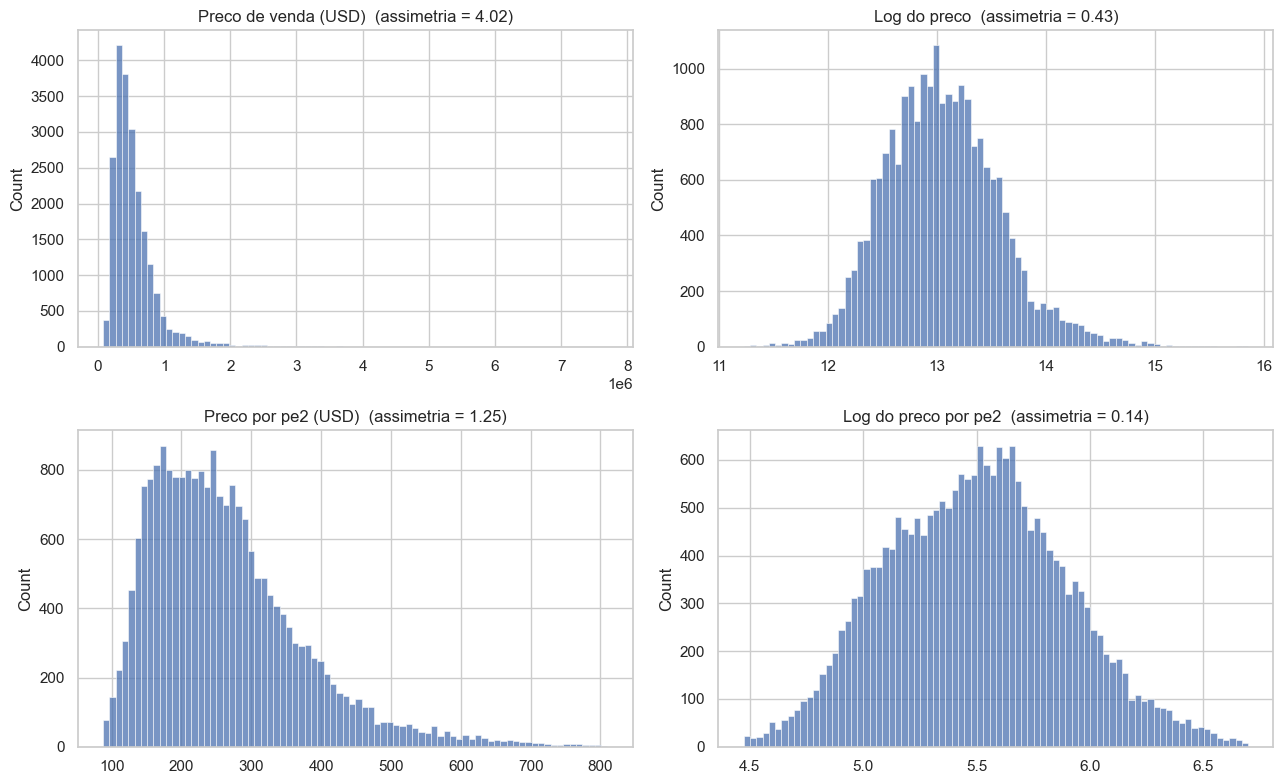

In [3]:
alvos = ["price", "log_price", "price_sqft", "log_price_sqft"]

medias = casas.select([F.avg(col(a)).alias(a) for a in alvos]).first().asDict()
momentos = casas.select(
    [F.avg((col(a) - medias[a]) ** 2).alias(f"{a}_m2") for a in alvos] +
    [F.avg((col(a) - medias[a]) ** 3).alias(f"{a}_m3") for a in alvos]
).first().asDict()

assimetria = {a: momentos[f"{a}_m3"] / momentos[f"{a}_m2"] ** 1.5 for a in alvos}
nativa = casas.select([F.skewness(col(a)).alias(a) for a in alvos]).first().asDict()

display(pd.DataFrame({
    "media": medias,
    "momento_2 (variancia)": {a: momentos[f"{a}_m2"] for a in alvos},
    "momento_3": {a: momentos[f"{a}_m3"] for a in alvos},
    "assimetria (calculada)": assimetria,
    "assimetria (F.skewness)": nativa,
}).round(4).rename(index=rotulo).reset_index(names="alvo"))

pdf = to_pd(casas, alvos)
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for a, nome in zip(ax.flat, alvos):
    sns.histplot(pdf[nome], bins=80, ax=a)
    a.set(title=f"{rotulo(nome)}  (assimetria = {assimetria[nome]:.2f})", xlabel="")
plt.tight_layout()
plt.show()

O preço tem forte assimetria à direita (4,0): mediana de 450 mil e máximo de 7,7 milhões. Modelar diretamente o preço faria os poucos imóveis de luxo dominarem o erro.

| Alvo | Assimetria | Leitura |
|---|---|---|
| price | 4,03 | Cauda longa, inadequado como alvo direto |
| price / sqft | 1,25 | Remove o efeito do tamanho, mas ainda assimétrico |
| log(price) | 0,43 | Próximo da normal |
| log(price / sqft) | 0,14 | O mais simétrico |

`log(price / sqft)` tem a distribuição mais bem comportada e remove do alvo o efeito do tamanho, de modo que o modelo aprende o valor do pé² (que depende de localização e padrão). A escolha final entre os alvos é feita na modelagem: cada alvo é parametrizado com validação cruzada e comparado no holdout, sempre pelo erro no preço real.

A assimetria é medida pelo coeficiente de skewness (terceiro momento padronizado):

$$\text{skew} = \frac{\frac{1}{n}\sum(x_i - \bar{x})^3}{\left(\frac{1}{n}\sum(x_i - \bar{x})^2\right)^{3/2}}$$

Valores próximos de 0 indicam simetria; valores positivos indicam cauda longa à direita. Entre −0,5 e 0,5 a distribuição é considerada aproximadamente simétrica.

## 4. Outliers

A análise é feita em duas camadas:
1. **Estatística (IQR)**: identifica valores extremos em todas as variáveis numéricas.
2. **Consistência (regras de negócio)**: identifica registros impossíveis ou incoerentes, ou seja, erros.

In [4]:
numericas = ["price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "condition", "grade",
             "sqft_above", "sqft_basement", "yr_built", "yr_renovated", "sqft_living15", "sqft_lot15"]

quartis = curto(casas).approxQuantile(numericas, [0.25, 0.75], 0.0)
limites = {c: (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)) for c, (q1, q3) in zip(numericas, quartis)}

contagem = casas.select([
    F.sum(((col(c) < lo) | (col(c) > hi)).cast("int")).alias(c) for c, (lo, hi) in limites.items()
]).first().asDict()

iqr = pd.DataFrame({
    "limite_inferior": {c: lo for c, (lo, hi) in limites.items()},
    "limite_superior": {c: hi for c, (lo, hi) in limites.items()},
    "qtd_fora": contagem,
})
iqr["pct_fora"] = (iqr.qtd_fora / n * 100).round(1)
display(iqr.sort_values("pct_fora", ascending=False).rename(index=rotulo).reset_index(names="coluna"))

,coluna,limite_inferior,limite_superior,qtd_fora,pct_fora
0,Area do terreno (pes2),-3432.000,19160.000,2425,11.2
1,Area do terreno media dos 15 vizinhos (pes2),-2374.500,17557.500,2194,10.2
2,Padrao construtivo (1 a 13),5.500,9.500,1911,8.8
3,Preco de venda (USD),-162625.000,1129575.000,1146,5.3
4,Ano da reforma (0 = nunca),0.000,0.000,914,4.2
5,Area acima do solo (pes2),-340.000,3740.000,611,2.8
6,Banheiros (0.5 = lavabo),0.625,3.625,571,2.6
7,Area util (pes2),-257.500,4234.500,572,2.6
8,Area util media dos 15 vizinhos (pes2),185.000,3665.000,544,2.5
9,Quartos,1.500,5.500,546,2.5


,Quartos,imoveis,pct,pct_acumulado
0,0,13,0.06,0.06
1,1,199,0.92,0.98
2,2,2760,12.77,13.75
3,3,9824,45.45,59.20
4,4,6882,31.84,91.04
5,5,1601,7.41,98.45
6,6,272,1.26,99.71
7,7,38,0.18,99.89
8,8,13,0.06,99.95
9,9,6,0.03,99.98


,percentil,Area util (pes2)
0,p50,1910.0
1,p90,3250.0
2,p95,3760.0
3,p99,4980.0
4,p99.9,7320.0
5,p100,13540.0


,Area util (pes2) acima de,imoveis
0,4000,783
1,5000,211
2,6000,68
3,8000,9
4,10000,3


,Identificador do imovel,Preco de venda (USD),Preco por pe2 (USD),Quartos,Banheiros (0.5 = lavabo),Area util (pes2),Area do terreno (pes2),Padrao construtivo (1 a 13),CEP
0,1225069038,2280000.0,168.389956,7,8.00,13540,307752,12,98053
1,6762700020,7700000.0,639.004149,6,8.00,12050,27600,13,98102
2,9808700762,7062500.0,703.436255,5,4.50,10040,37325,11,98004
3,9208900037,6885000.0,696.157735,6,7.75,9890,31374,13,98039
4,1924059029,4668000.0,484.232365,5,6.75,9640,13068,12,98040
5,2470100110,5570000.0,605.434783,5,5.75,9200,35069,13,98039
6,2303900035,2888000.0,333.102653,5,6.25,8670,64033,13,98177
7,6072800246,3300000.0,411.471322,5,6.25,8020,21738,11,98006
8,1247600105,5110800.0,638.052434,5,5.25,8010,45517,12,98033
9,8907500070,5350000.0,668.750000,5,5.00,8000,23985,12,98004


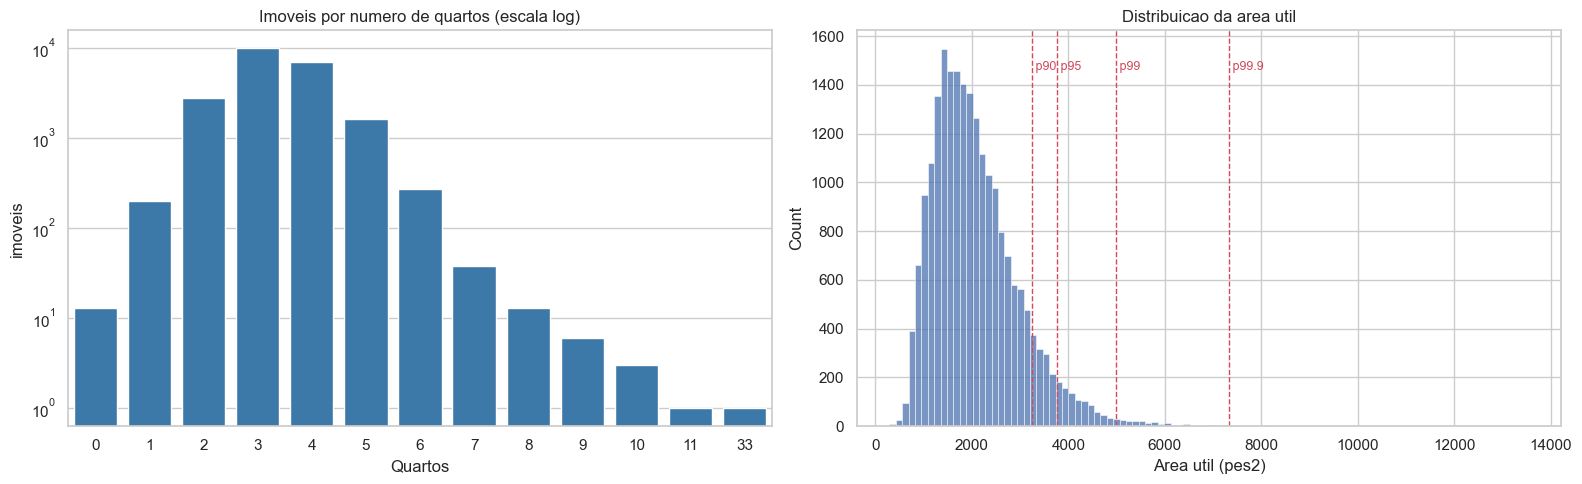

In [5]:
base = curto(casas)

quartos = (base.groupBy("bedrooms")
               .agg(F.count("*").alias("imoveis"))
               .withColumn("pct", F.round(100 * F.col("imoveis") / n, 2))
               .orderBy("bedrooms")
               .toPandas())
quartos["pct_acumulado"] = quartos.pct.cumsum().round(2)
display(quartos.rename(columns=rotulo))

percentis = [0.5, 0.9, 0.95, 0.99, 0.999, 1.0]
valores = base.approxQuantile("sqft_living", percentis, 0.0)
limites = [4000, 5000, 6000, 8000, 10000]
acima = base.select([F.sum((F.col("sqft_living") > t).cast("int")).alias(str(t)) for t in limites]).first().asDict()

display(pd.DataFrame({"percentil": [f"p{p * 100:g}" for p in percentis], rotulo("sqft_living"): valores}))
display(pd.DataFrame({f"{rotulo('sqft_living')} acima de": limites, "imoveis": [acima[str(t)] for t in limites]}))

display(base.orderBy(F.col("sqft_living").desc())
            .select("id", "price", "price_sqft", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "grade", "zipcode")
            .limit(10)
            .toPandas()
            .rename(columns=rotulo))

pdf = to_pd(casas, ["bedrooms", "sqft_living"])
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(x=pdf.bedrooms, ax=ax[0], color="#2b7bba")
ax[0].set(yscale="log", title="Imoveis por numero de quartos (escala log)", xlabel=rotulo("bedrooms"), ylabel="imoveis")
sns.histplot(pdf.sqft_living, bins=100, ax=ax[1])
for p, v in zip(percentis[1:-1], valores[1:-1]):
    ax[1].axvline(v, color="#d1495b", ls="--", lw=1)
    ax[1].text(v, ax[1].get_ylim()[1] * 0.9, f" p{p * 100:g}", color="#d1495b", fontsize=9)
ax[1].set(title="Distribuicao da area util", xlabel=rotulo("sqft_living"))
plt.tight_layout()
plt.show()

### Distribuição de quartos e área útil

- Imóveis com 2 a 5 quartos representam 97,5% da base. Com 7 ou mais quartos há apenas 63 imóveis (0,3%).
- A área útil tem mediana de 1.910 pés², p99 de 4.980 e p99,9 de 7.320 pés². Apenas 9 imóveis têm mais de 8.000 pés².
- A maior casa da base (13.540 pés²) tem preço por pé² de 168 USD, muito abaixo das demais casas grandes de padrão semelhante (entre 330 e 700 USD). O terreno de 307 mil pés² sugere uma propriedade rural, mas o registro destoa do seu grupo.
- Os imóveis do unseen estão dentro da faixa comum (até 4.580 pés² e 6 quartos).

Esses imóveis extremos são reais e poucos, então o modelo terá pouca informação para aprender essa faixa. A remoção não é feita na EDA: o impacto de manter ou excluir os imóveis muito grandes é avaliado na modelagem, sempre com o mesmo conjunto de teste.

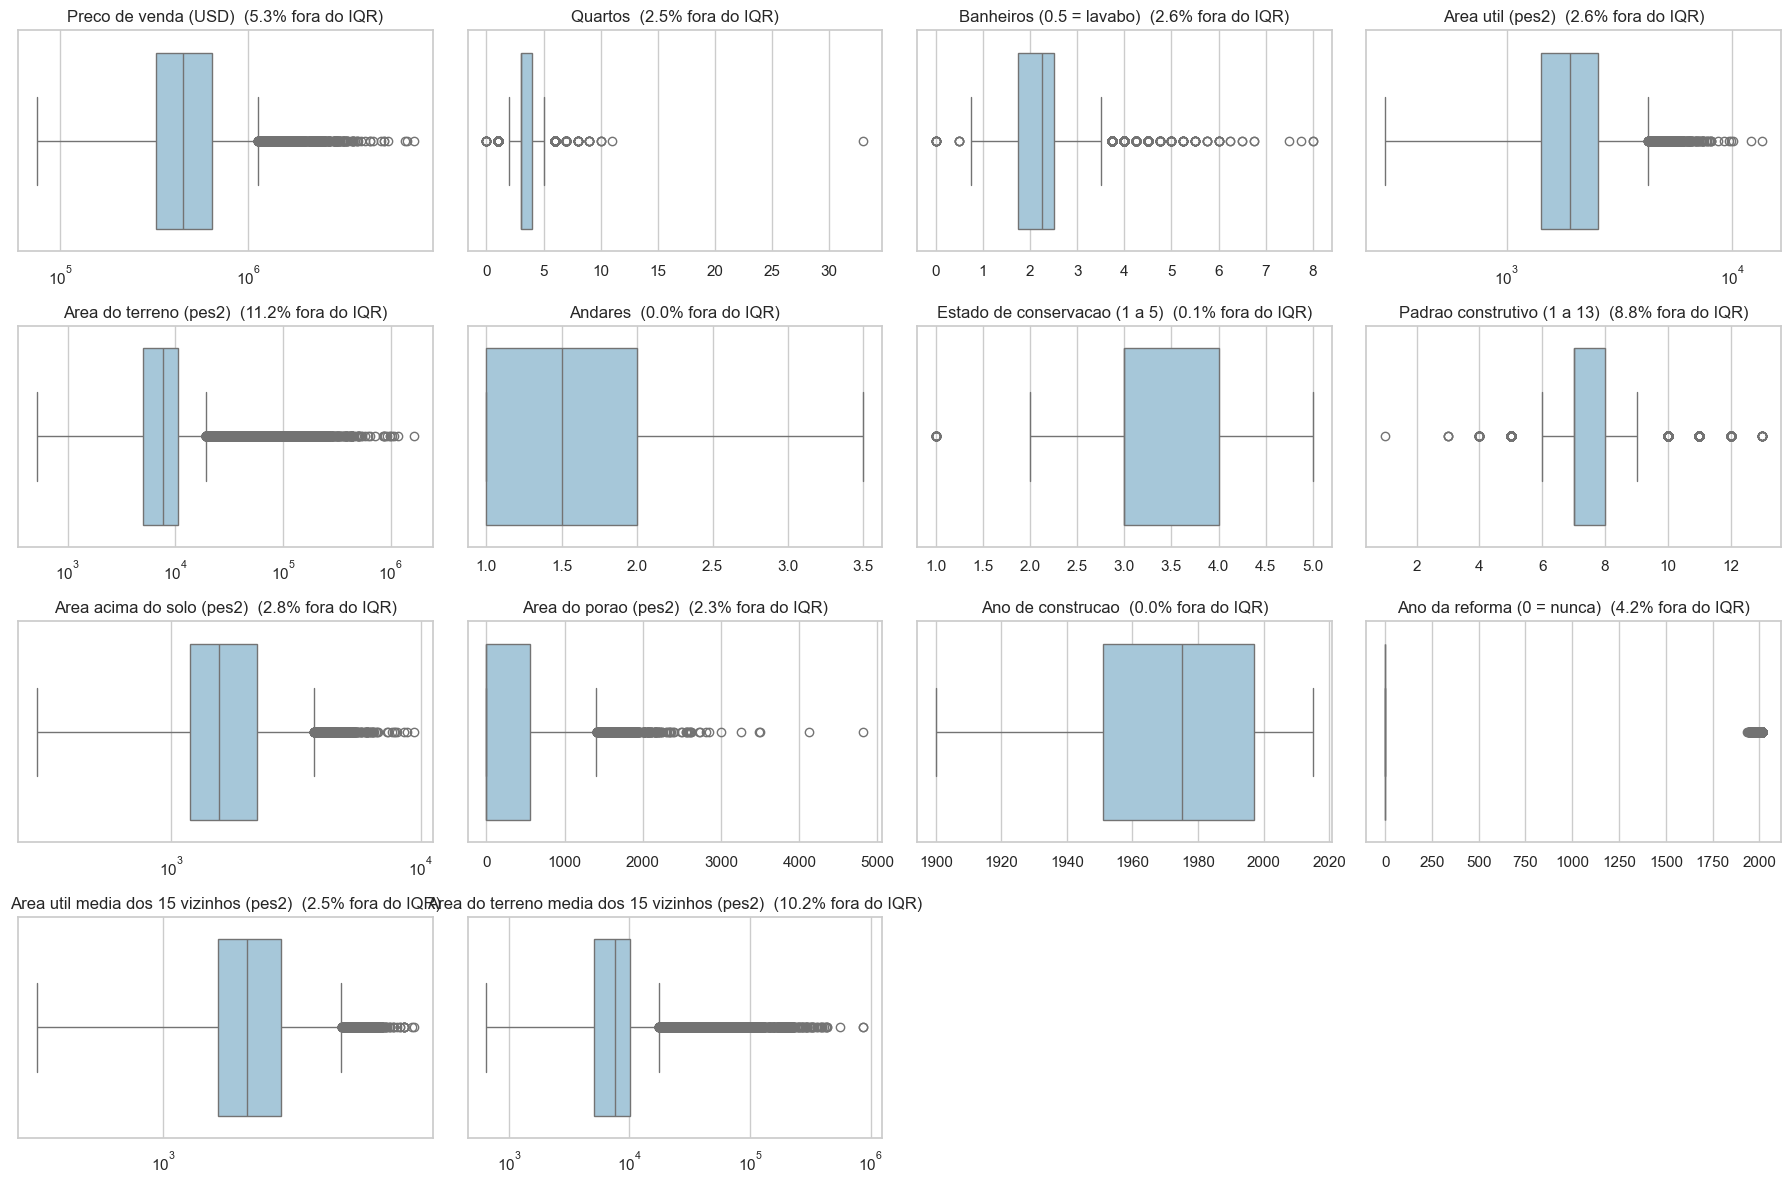

In [6]:
pdf = to_pd(casas, numericas)
log = {"price", "sqft_living", "sqft_lot", "sqft_above", "sqft_living15", "sqft_lot15"}

ncols = 4
nrows = int(np.ceil(len(numericas) / ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(18, 3 * nrows))
for a, c in zip(ax.flat, numericas):
    sns.boxplot(x=pdf[c], ax=a, color="#9ecae1")
    a.set(title=f"{rotulo(c)}  ({iqr.loc[c, 'pct_fora']}% fora do IQR)", xlabel="")
    if c in log:
        a.set_xscale("log")
for a in ax.flat[len(numericas):]:
    a.axis("off")
plt.tight_layout()
plt.show()

### 4.1 Camada estatística

| Coluna | % fora do IQR | Leitura |
|---|---|---|
| sqft_lot / sqft_lot15 | 11,2% / 10,2% | Cauda longa real: propriedades rurais com terrenos grandes |
| grade | 8,8% | Imóveis de padrão muito alto ou muito baixo, reais |
| price | 5,3% | Imóveis de alto padrão, reais |
| yr_renovated | 4,2% | Artefato: a coluna é 0 para quem nunca reformou, então qualquer reforma vira "outlier" |
| demais variáveis de área e cômodos | ~2,5% | Imóveis grandes |

Em distribuições assimétricas, o IQR marca como outlier uma parte relevante de registros que são reais. Removê-los por essa regra eliminaria justamente os imóveis de maior valor, que o modelo precisa aprender. **Nenhum registro é removido por critério estatístico.**

### 4.2 Camada de consistência

In [7]:
regras = {
    "0 quartos": col("bedrooms") == 0,
    "mais de 15 quartos": col("bedrooms") > 15,
    "0 banheiros": col("bathrooms") == 0,
    "banheiros > quartos + 3": col("bathrooms") > col("bedrooms") + 3,
    "reforma antes da construcao": (col("yr_renovated") > 0) & (col("yr_renovated") < col("yr_built")),
    "area util != acima do solo + porao": col("sqft_living") != col("sqft_above") + col("sqft_basement"),
    "area util > terreno": col("sqft_living") > col("sqft_lot"),
}
resultado = casas.select([F.sum(r.cast("int")).alias(k) for k, r in regras.items()]).first().asDict()
display(pd.Series(resultado, name="casos").to_frame())

faixa = casas.agg(F.min(col("price_sqft")).alias("min"), F.max(col("price_sqft")).alias("max")).first()
print(f"Preco por pe2: de {faixa['min']:.0f} a {faixa['max']:.0f} USD")

,casos
0 quartos,13
mais de 15 quartos,1
0 banheiros,10
banheiros > quartos + 3,0
reforma antes da construcao,0
area util != acima do solo + porao,0
area util > terreno,789


Preco por pe2: de 88 a 810 USD


In [8]:
inconsistente = regras["0 quartos"] | regras["mais de 15 quartos"] | regras["0 banheiros"]
display(casas.filter(inconsistente)
             .select(col("id"), col("price"), col("bedrooms"), col("bathrooms"), col("sqft_living"), col("grade"))
             .orderBy(col("bedrooms").desc())
             .toPandas()
             .rename(columns=lambda c: rotulo(c.split(" - ")[0])))

,Identificador do imovel,Preco de venda (USD),Quartos,Banheiros (0.5 = lavabo),Area util (pes2),Padrao construtivo (1 a 13)
0,2402100895,640000.0,33,1.75,1620,7
1,3421079032,75000.0,1,0.00,670,3
2,5702500050,280000.0,1,0.00,600,3
3,203100435,484000.0,1,0.00,690,7
4,6306400140,1095000.0,0,0.00,3064,7
5,3918400017,380000.0,0,0.00,1470,8
6,1453602309,288000.0,0,1.50,1430,7
7,6896300380,228000.0,0,1.00,390,4
8,2954400190,1295650.0,0,0.00,4810,12
9,2569500210,339950.0,0,2.50,2290,8


In [9]:
display(casas.filter(regras["area util > terreno"])
             .groupBy(col("floors").alias("andares"))
             .agg(F.count("*").alias("imoveis"),
                  F.round(F.avg(col("sqft_lot")), 0).alias("terreno_medio_pes2"))
             .orderBy("andares"))

,andares,imoveis,terreno_medio_pes2
0,1.0,4,2044.0
1,1.5,7,1579.0
2,2.0,391,1313.0
3,2.5,32,1557.0
4,3.0,349,1230.0
5,3.5,6,1299.0


| Regra | Casos | Leitura |
|---|---|---|
| 0 quartos | 13 | Improvável para imóvel residencial |
| Mais de 15 quartos | 1 | 33 quartos em 1.620 pés²: provável erro de digitação |
| 0 banheiros | 10 | Improvável para imóvel residencial (7 também têm 0 quartos) |
| Banheiros > quartos + 3 | 0 | |
| Reforma antes da construção | 0 | |
| Área útil ≠ acima do solo + porão | 0 | `sqft_living` é exatamente a soma das duas, uma redundância |
| Área útil > terreno | 789 | Plausível: quase todos são sobrados e townhouses de 2 a 3 andares em terrenos pequenos |

O preço por pé² varia de 88 a 810 USD, sem valores implausíveis.

**Conclusão:** apesar de muitos valores extremos, apenas **17 registros** (0,08% da base) são inconsistentes: 0 quartos, 0 banheiros ou 33 quartos. Eles são removidos na preparação da base.

## 5. Junção dos dados físicos e demográficos

In [10]:
ceps_casas = casas.select(col("zipcode")).distinct()
print("CEPs na base de imoveis:", ceps_casas.count(), "| CEPs na demografia:", demo.count())
print("CEPs sem demografia (treino):", ceps_casas.join(demo, on=C["zipcode"], how="left_anti").count())
print("CEPs sem demografia (unseen):", unseen.select(col("zipcode")).distinct().join(demo, on=C["zipcode"], how="left_anti").count())

cols_demo = [F.col(f"`{c}`") for c in demo.columns if c != C["zipcode"]]
display(demo.groupBy(cols_demo)
            .agg(F.collect_list(col("zipcode")).alias("ceps"), F.count("*").alias("qtd"))
            .filter("qtd > 1")
            .select("ceps", "qtd"))

print("Colunas do treino ausentes no unseen:",
      [rotulo(c.split(" - ")[0]) for c in casas.columns if c not in unseen.columns])

CEPs na base de imoveis: 70 | CEPs na demografia: 70
CEPs sem demografia (treino): 0
CEPs sem demografia (unseen): 0


,ceps,qtd
0,"[98074, 98077, 98030, 98075]",4


Colunas do treino ausentes no unseen: ['Identificador do imovel', 'Data da venda', 'Preco de venda (USD)', 'Log do preco', 'Preco por pe2 (USD)', 'Log do preco por pe2']


In [11]:
df = casas.join(demo, on=C["zipcode"], how="left")
print("Linhas apos o join:", df.count(), "| antes:", n)

Linhas apos o join: 21613 | antes: 21613


- A junção é feita por **CEP** (left join dos imóveis com a demografia), com cobertura de 100% tanto no treino quanto no unseen, e sem duplicar linhas.
- Os CEPs **98074, 98077, 98030 e 98075** possuem valores demográficos idênticos, com decimais como 23926.5, o que indica imputação pela média na origem. Para esses CEPs a demografia não traz informação real. Isso fica registrado como limitação.
- O unseen não possui `id`, `date` nem o preço. Por isso `date` não pode ser usada como variável do modelo.

## 6. Correlações com o preço

A correlação de Pearson mede apenas relação **linear** e é sensível a assimetria e valores extremos, características presentes no preço. Por isso ela é comparada com a correlação de **Spearman**, calculada sobre o ranking dos valores, que capta qualquer relação monotônica.

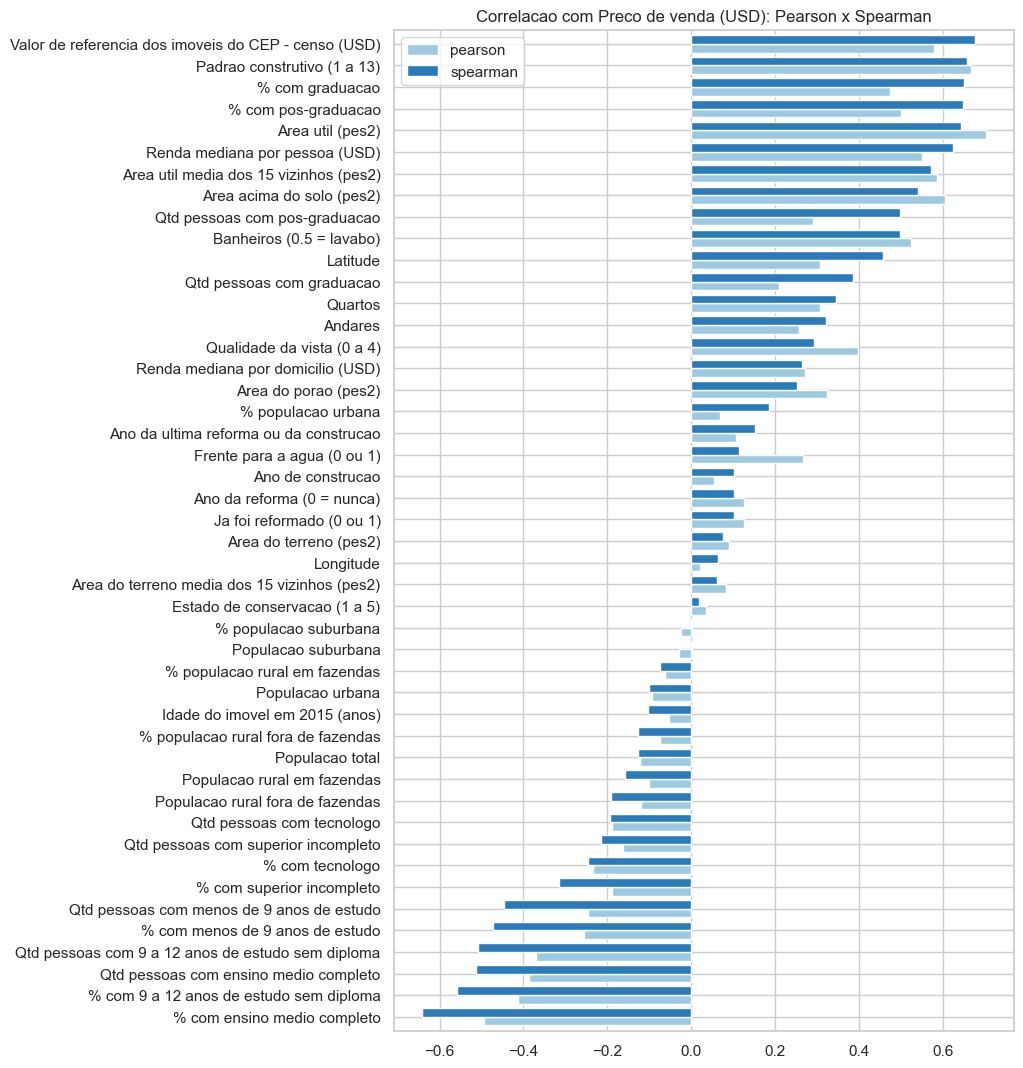

In [12]:
fora = {"id", "date", "zipcode", "log_price", "price_sqft", "log_price_sqft"}
nomes = [c.split(" - ")[0] for c in df.columns if c.split(" - ")[0] not in fora]

vetor = (VectorAssembler(inputCols=nomes, outputCol="v")
         .transform(curto(df).select(nomes)).select("v"))
pearson = Correlation.corr(vetor, "v", "pearson").first()[0].toArray()
spearman = Correlation.corr(vetor, "v", "spearman").first()[0].toArray()

i = nomes.index("price")
corr = pd.DataFrame({"pearson": pearson[i], "spearman": spearman[i]}, index=nomes).drop("price")
corr["diferenca"] = corr.spearman - corr.pearson
corr = corr.reindex(corr.spearman.abs().sort_values(ascending=False).index)

ax = (corr[["pearson", "spearman"]].sort_values("spearman").rename(index=rotulo)
      .plot.barh(figsize=(8, 13), width=0.8, color=["#9ecae1", "#2b7bba"]))
ax.set(title=f"Correlacao com {rotulo('price')}: Pearson x Spearman")
plt.show()

Na correlação individual, `condition` parece não ter relação com o preço. A seção 8.5 mostra que esse efeito existe, mas fica escondido pela idade e pelo padrão do imóvel.

In [13]:
display(corr.round(2).rename(index=rotulo).reset_index(names="variavel"))

,variavel,pearson,spearman,diferenca
0,Valor de referencia dos imoveis do CEP - censo...,0.58,0.68,0.10
1,Padrao construtivo (1 a 13),0.67,0.66,-0.01
2,% com graduacao,0.47,0.65,0.18
3,% com pos-graduacao,0.50,0.65,0.15
4,Area util (pes2),0.70,0.64,-0.06
5,% com ensino medio completo,-0.49,-0.64,-0.15
6,Renda mediana por pessoa (USD),0.55,0.62,0.07
7,Area util media dos 15 vizinhos (pes2),0.59,0.57,-0.01
8,% com 9 a 12 anos de estudo sem diploma,-0.41,-0.56,-0.15
9,Area acima do solo (pes2),0.61,0.54,-0.06


- **Variáveis físicas** mais associadas ao preço: `sqft_living`, `grade`, `sqft_above`, `sqft_living15` e `bathrooms`.
- **Variáveis demográficas** têm associação forte: valor de referência do CEP (`hous_val_amt`), renda per capita e escolaridade (`per_bchlr`, `per_prfsnl` positivas; `per_hsd` e `per_9_to_12` negativas).
- O Pearson **subestima** a demografia e a latitude: `per_bchlr` vai de 0,47 para 0,65, `lat` de 0,31 para 0,46 e `per_less_than_9` de −0,25 para −0,47. As relações existem, mas não são lineares.
- Já `waterfront` cai de 0,27 para 0,12: o Pearson era inflado por poucos imóveis de frente para a água com preços muito altos.

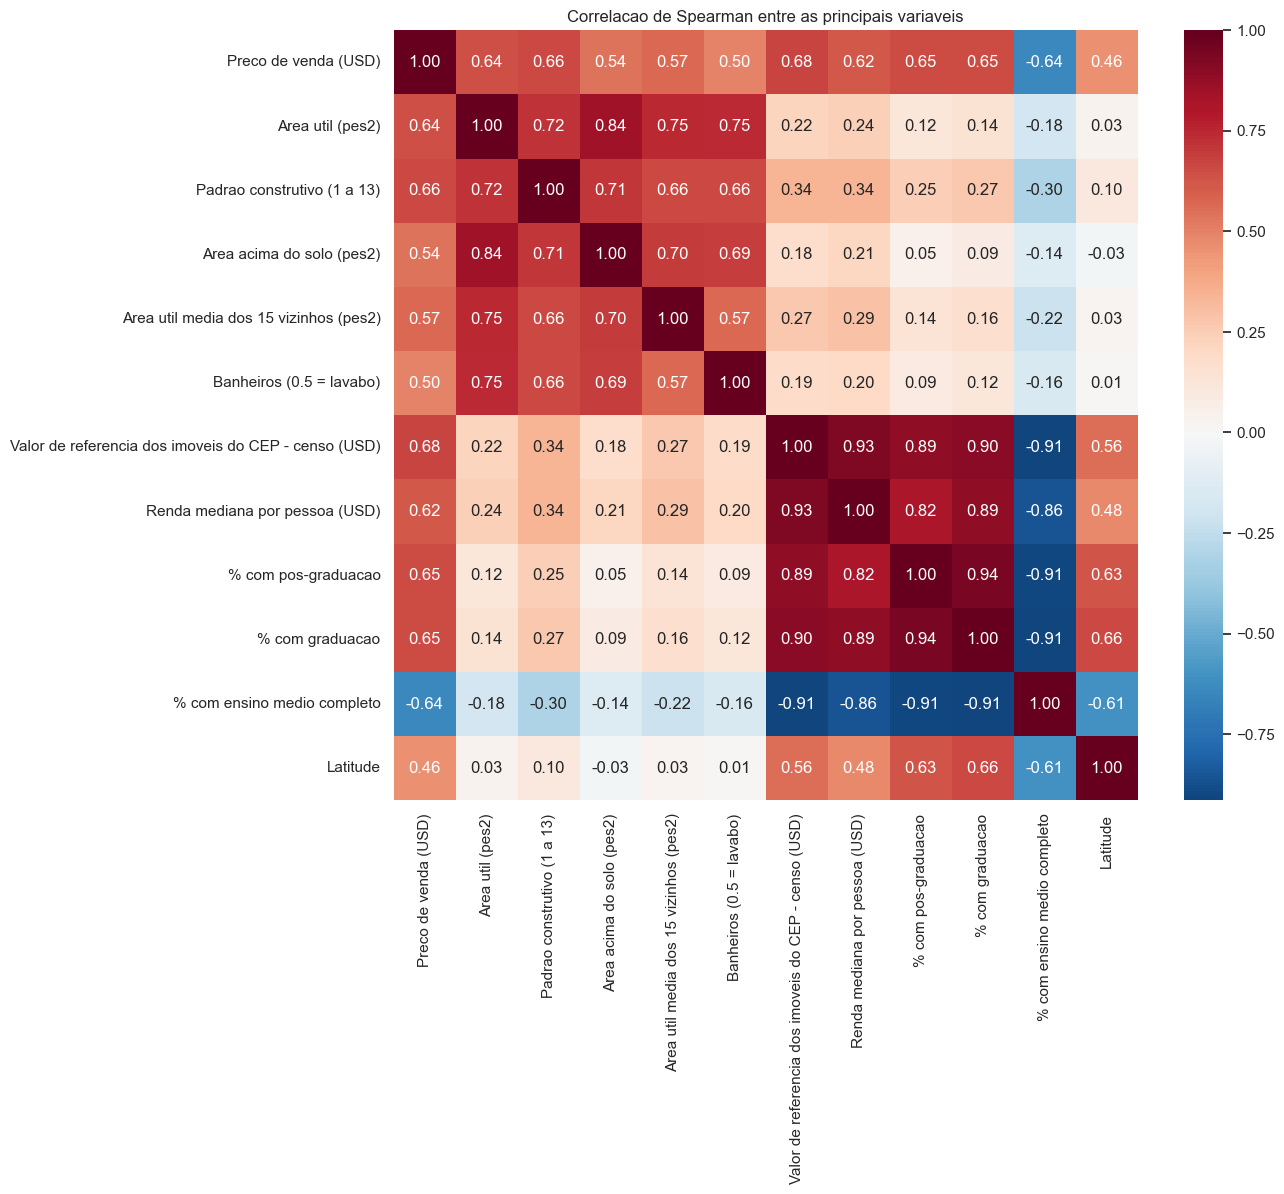

In [14]:
top = ["price", "sqft_living", "grade", "sqft_above", "sqft_living15", "bathrooms",
       "hous_val_amt", "medn_incm_per_prsn_amt", "per_prfsnl", "per_bchlr", "per_hsd", "lat"]
idx = [nomes.index(c) for c in top]
matriz = pd.DataFrame(spearman[np.ix_(idx, idx)], index=[rotulo(c) for c in top], columns=[rotulo(c) for c in top])

plt.figure(figsize=(12, 10))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlacao de Spearman entre as principais variaveis")
plt.show()

Há forte colinearidade entre as variáveis de área (`sqft_living`, `sqft_above`, `sqft_living15`) e entre as demográficas (renda, escolaridade e valor de referência). 

## 7. Padrões relevantes

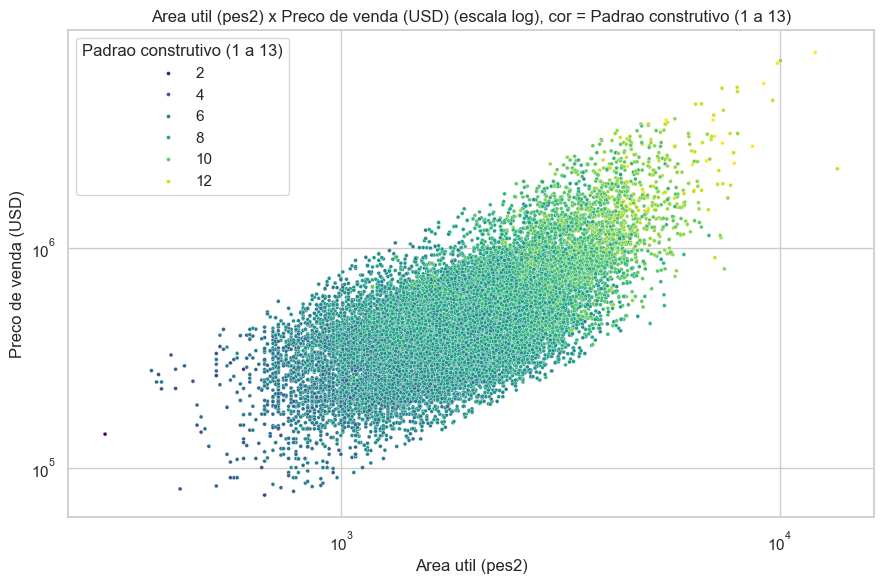

In [15]:
pdf = to_pd(casas, ["sqft_living", "price", "grade"])
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=pdf, x="sqft_living", y="price", hue="grade", palette="viridis", s=8, ax=ax)
ax.set(xscale="log", yscale="log", title=f"{rotulo('sqft_living')} x {rotulo('price')} (escala log), cor = {rotulo('grade')}",
       xlabel=rotulo("sqft_living"), ylabel=rotulo("price"))
ax.legend(title=rotulo("grade"))
plt.tight_layout()
plt.show()

A relação entre área e preço é aproximadamente linear em escala log-log: o preço cresce de forma proporcional à área. A cor mostra que, para a mesma área, imóveis de `grade` mais alto valem mais.

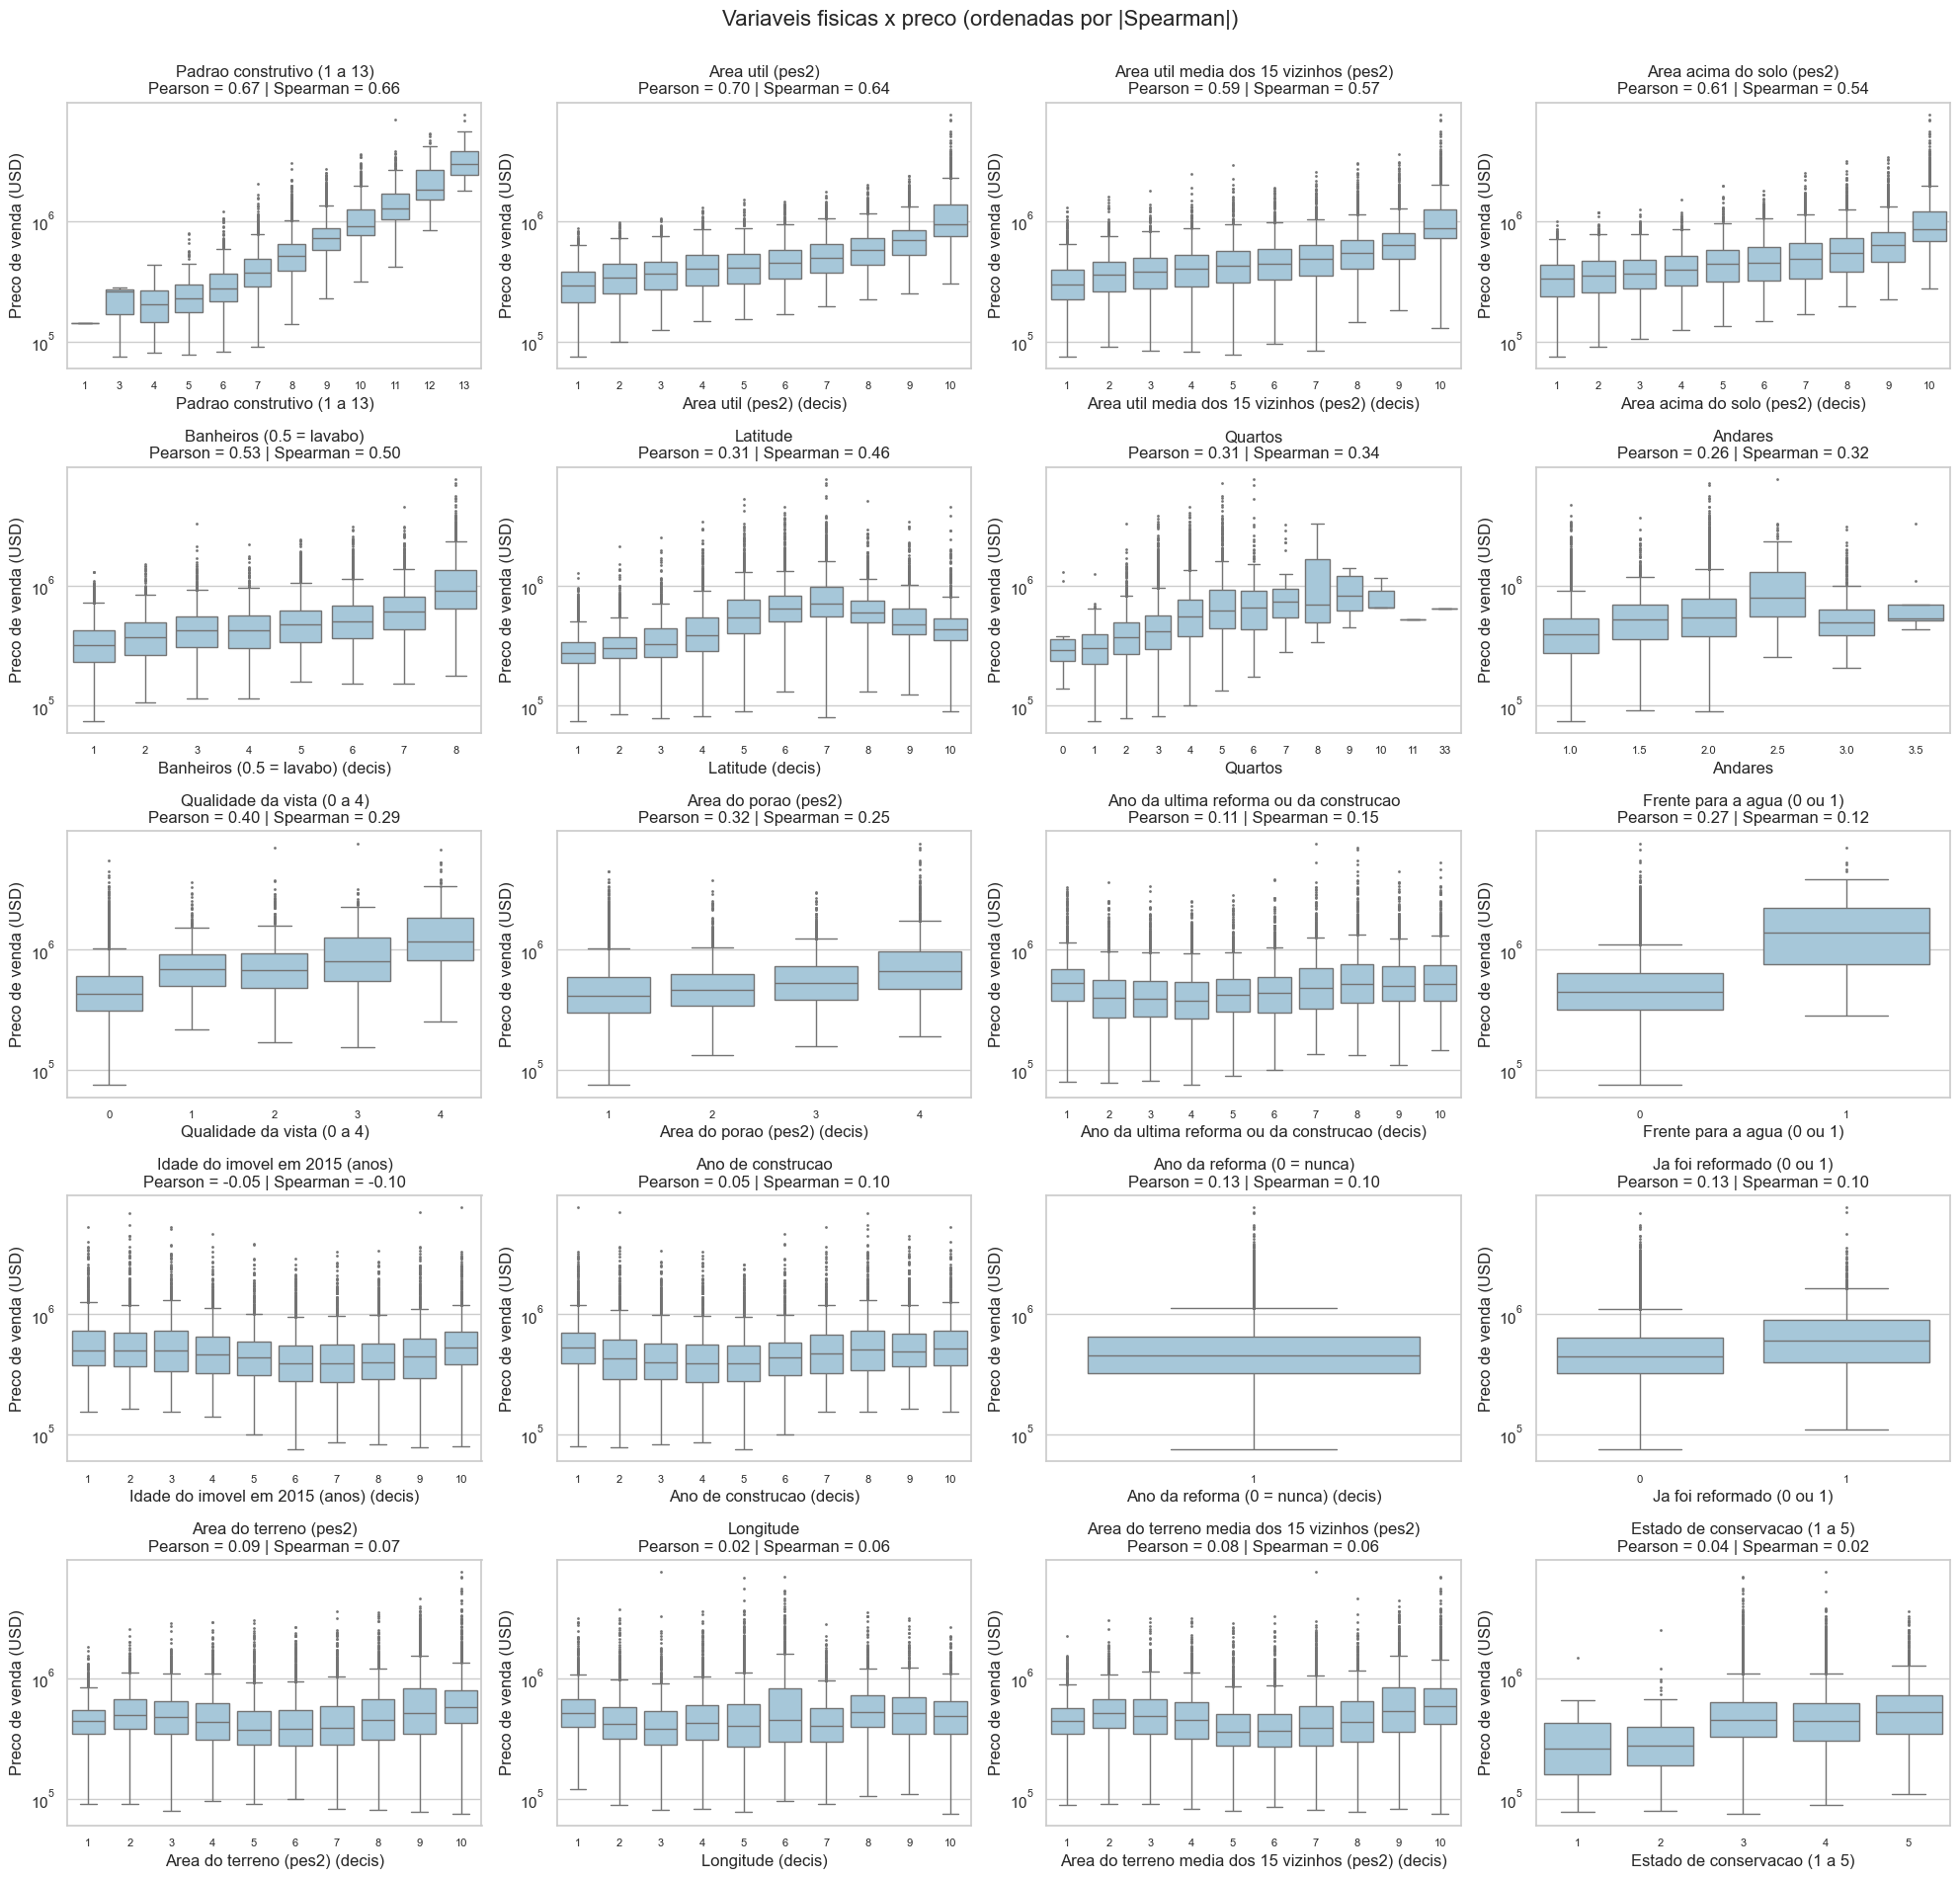

In [16]:
def boxplots_vs_preco(pdf, cols, titulo, n_col=4, max_categorias=15):
    n_lin = int(np.ceil(len(cols) / n_col))
    fig, ax = plt.subplots(n_lin, n_col, figsize=(5 * n_col, 3.8 * n_lin))
    for a, c in zip(ax.flat, cols):
        if pdf[c].nunique() <= max_categorias:
            x, eixo = pdf[c], rotulo(c)
        else:
            x, eixo = pd.qcut(pdf[c], 10, labels=False, duplicates="drop") + 1, f"{rotulo(c)} (decis)"
        sns.boxplot(x=x, y=pdf["price"], ax=a, color="#9ecae1", fliersize=1)
        a.set(yscale="log", xlabel=eixo, ylabel=rotulo("price"),
              title=f"{rotulo(c)}\nPearson = {corr.loc[c, 'pearson']:.2f} | Spearman = {corr.loc[c, 'spearman']:.2f}")
        a.tick_params(axis="x", labelsize=8)
    for a in ax.flat[len(cols):]:
        a.set_visible(False)
    fig.suptitle(titulo, fontsize=16, y=1.0)
    plt.tight_layout()
    plt.show()

pdf = curto(df).select(["price"] + list(corr.index)).toPandas()
fisicas = [c for c in corr.index if C[c] in casas.columns]
demograficas = [c for c in corr.index if c not in fisicas]

boxplots_vs_preco(pdf, fisicas, "Variaveis fisicas x preco (ordenadas por |Spearman|)")

- **grade** e as variáveis de área têm relação crescente e consistente com o preço. `grade` tem efeito em degraus: a mediana passa de cerca de 375 mil (grade 7) para cerca de 3 milhões (grade 13).
- **waterfront** triplica a mediana do preço (de 450 mil para 1,4 milhão), mas são apenas 163 imóveis.
- **view** tem efeito crescente com a nota.
- **lat** não é monotônica: o preço sobe até o 7º decil e depois cai. As regiões centrais (Seattle, Bellevue) são mais caras e o extremo norte volta a ser mais barato. O Spearman (0,46) mede apenas se a relação é sempre crescente e subestima esse formato.
- **yr_built** tem formato de U: imóveis antigos (em bairros consolidados) e novos valem mais que os construídos nas décadas de 1950 a 1970, apesar da correlação de apenas 0,10.
- **condition** parece ter efeito pequeno no gráfico geral, mas isso é um fator de confusão com a idade e o padrão (ver 8.5).

Variáveis com correlação baixa podem ter relação forte, mas não linear nem monotônica. Isso reforça o uso de modelos de árvore.

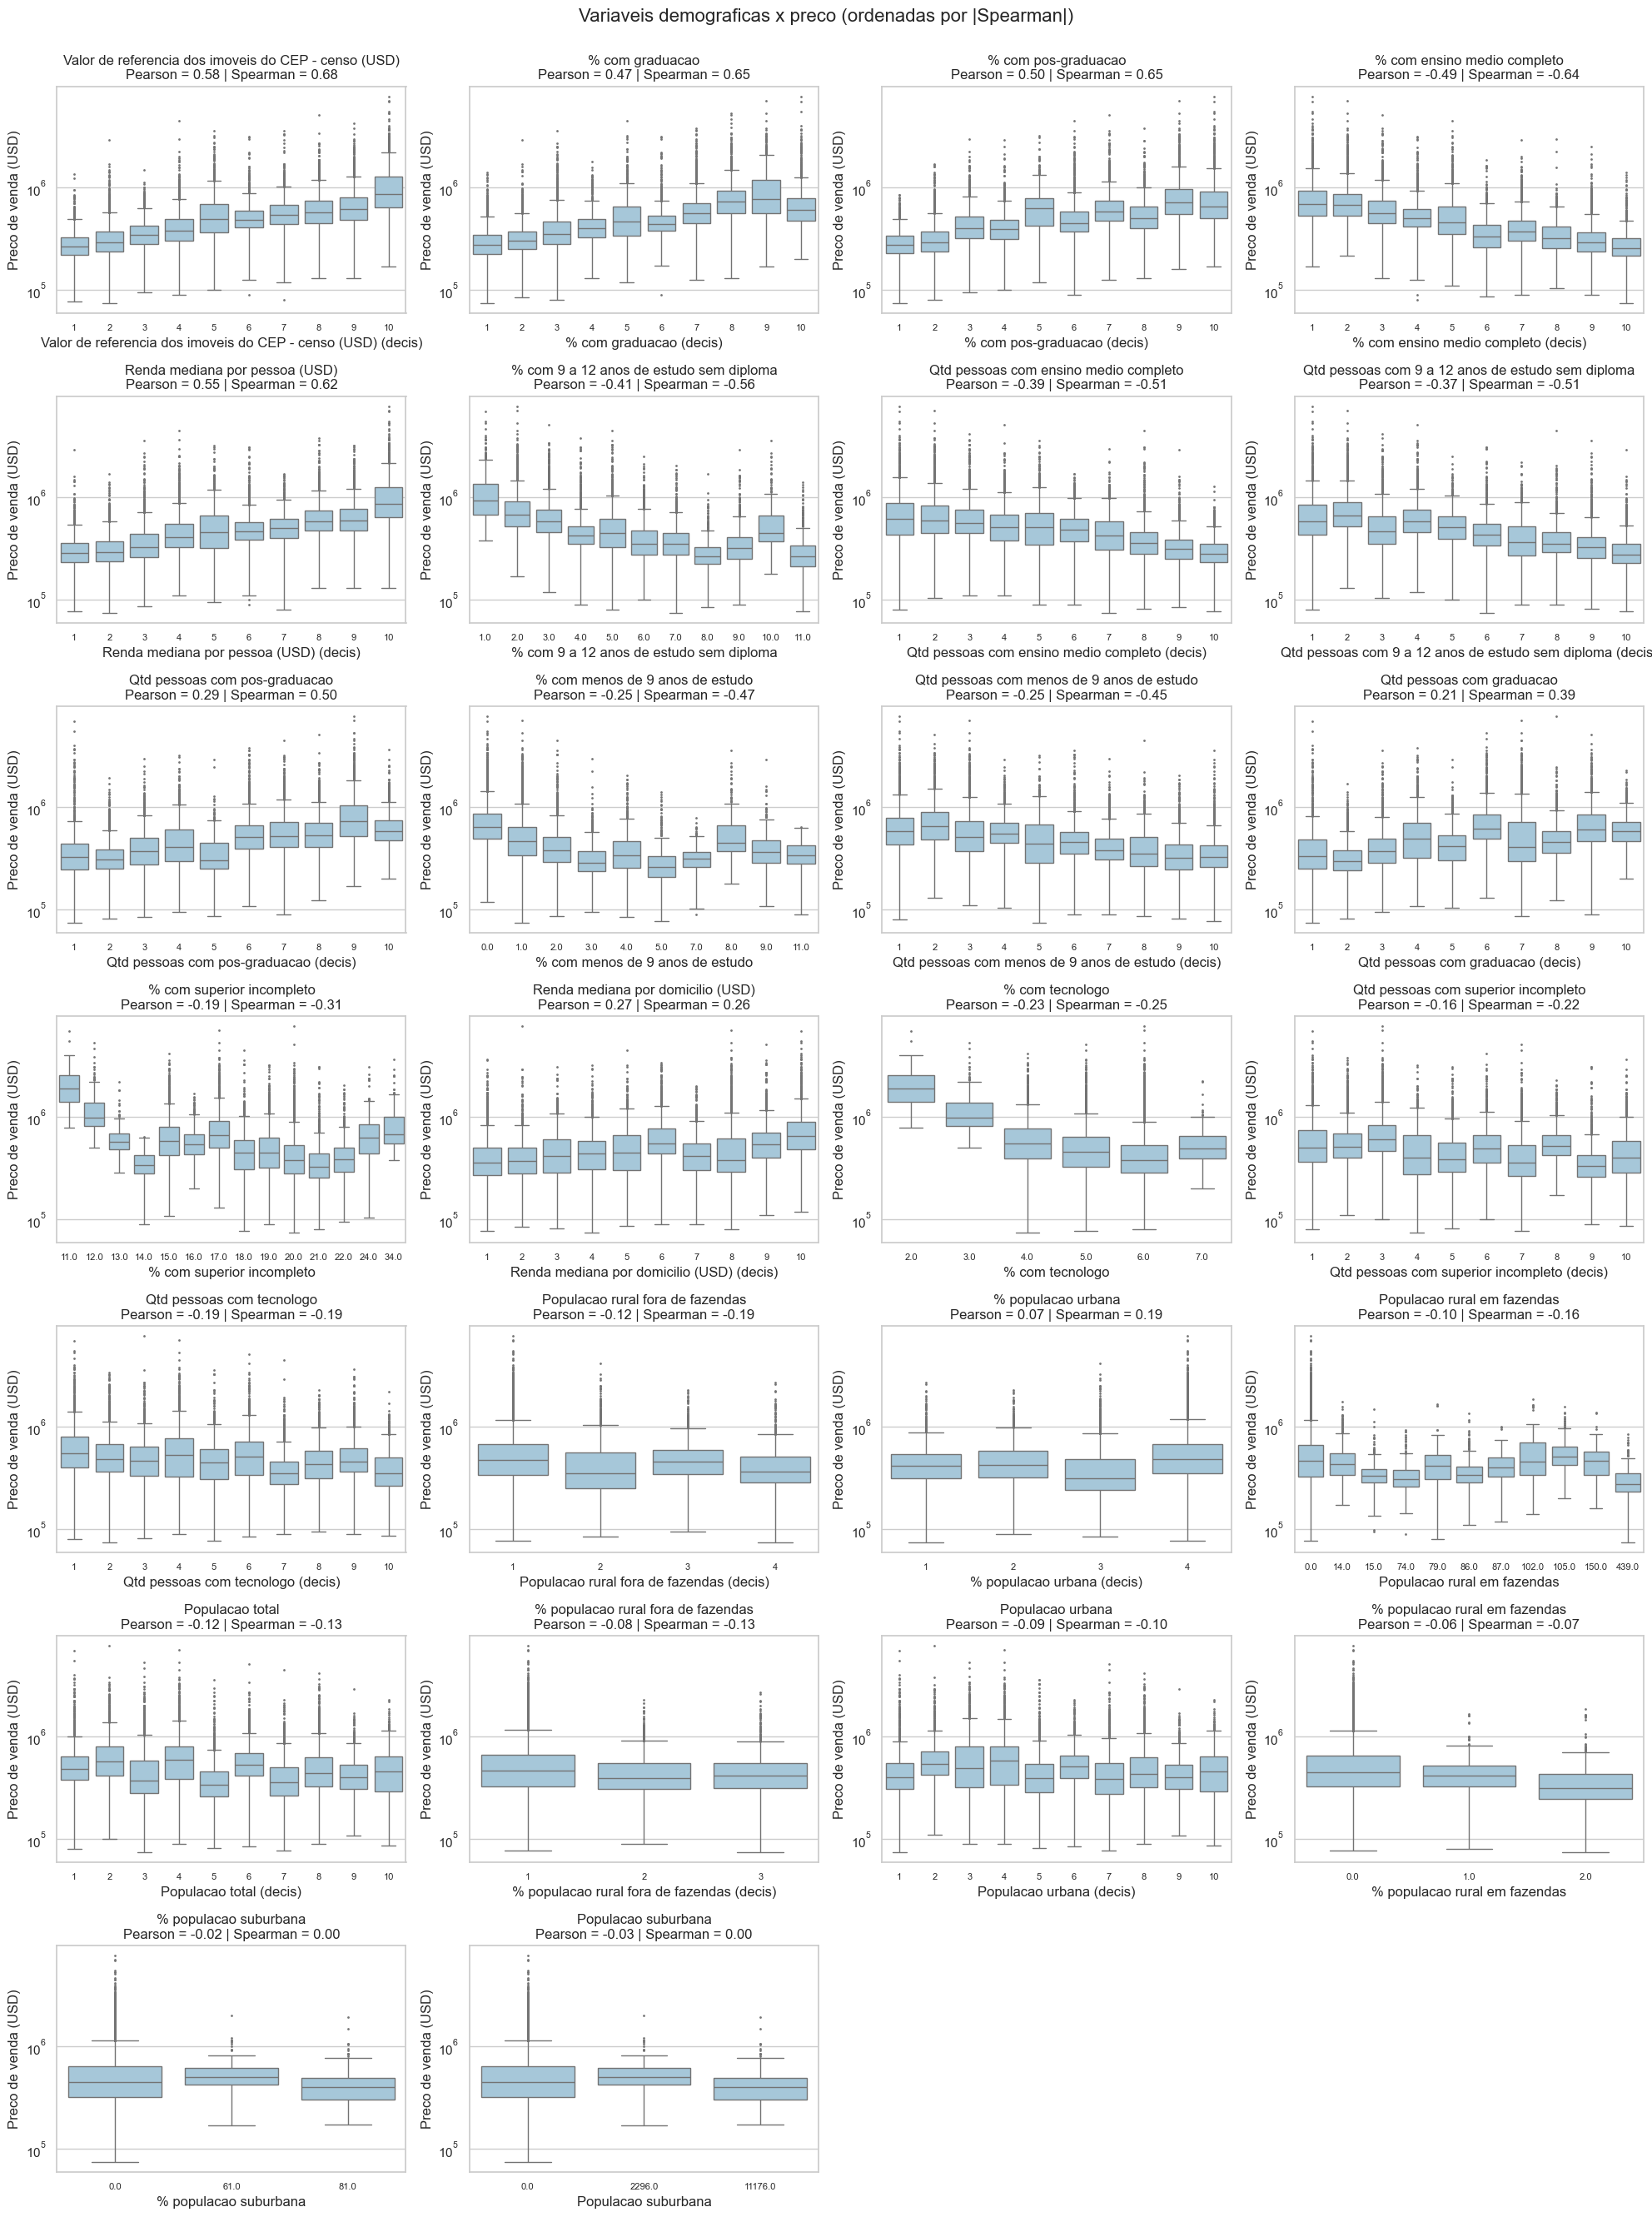

In [17]:
boxplots_vs_preco(pdf, demograficas, "Variaveis demograficas x preco (ordenadas por |Spearman|)")

- Valor de referência do CEP, renda per capita e escolaridade superior têm relação crescente com o preço. Escolaridade baixa (`per_hsd`, `per_9_to_12`) tem relação decrescente.
- A renda mediana **por domicílio** (Spearman 0,26) é bem menos associada ao preço que a renda **por pessoa** (0,62), possivelmente porque a renda do domicílio depende também do número de moradores.
- As variáveis de composição da população (urbana, rural, suburbana, total) têm relação fraca com o preço.
- As contagens absolutas de escolaridade (`edctn_*_qty`) repetem a informação dos percentuais, com relação mais fraca por dependerem do tamanho da população do CEP.

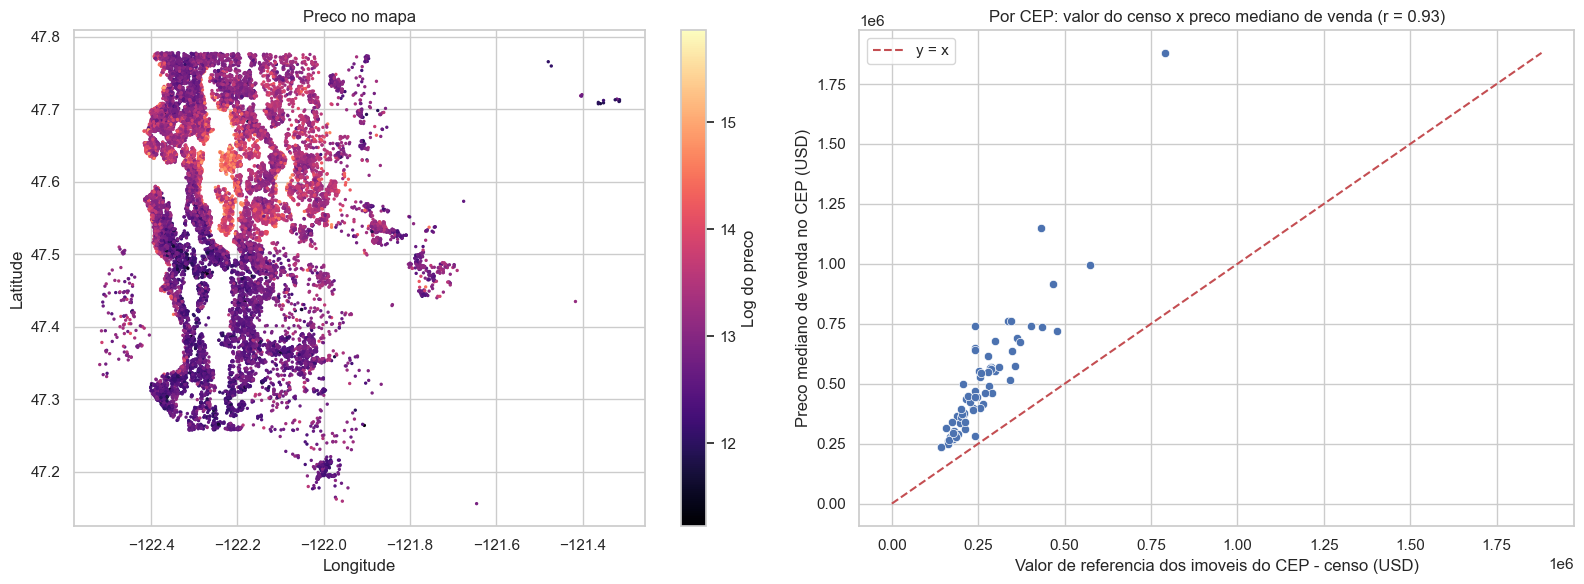

Razao mediana preco de venda / valor do censo: 1.82


In [18]:
pdf = to_pd(casas, ["lat", "long", "log_price"])
por_cep = (df.groupBy(col("zipcode").alias("zipcode"))
             .agg(F.percentile_approx(col("price"), 0.5).alias("preco_mediano_venda"),
                  F.first(col("hous_val_amt")).alias("hous_val_amt"))
             .toPandas())

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sc = ax[0].scatter(pdf.long, pdf.lat, c=pdf.log_price, s=2, cmap="magma")
plt.colorbar(sc, ax=ax[0], label=rotulo("log_price"))
ax[0].set(title="Preco no mapa", xlabel=rotulo("long"), ylabel=rotulo("lat"))

r = por_cep[["hous_val_amt", "preco_mediano_venda"]].corr().iloc[0, 1]
sns.scatterplot(data=por_cep, x="hous_val_amt", y="preco_mediano_venda", ax=ax[1])
lim = [0, por_cep.preco_mediano_venda.max()]
ax[1].plot(lim, lim, "r--", label="y = x")
ax[1].legend()
ax[1].set(title=f"Por CEP: valor do censo x preco mediano de venda (r = {r:.2f})",
          xlabel=rotulo("hous_val_amt"), ylabel="Preco mediano de venda no CEP (USD)")
plt.tight_layout()
plt.show()

print("Razao mediana preco de venda / valor do censo:",
      round((por_cep.preco_mediano_venda / por_cep.hous_val_amt).median(), 2))

- **Mapa:** há um gradiente geográfico. O preço é mais alto na faixa central (Seattle, Bellevue, Medina e Mercer Island), cai bastante no sul do condado e um pouco no extremo norte. O efeito da latitude não é linear (ver o painel de variáveis físicas).

- **Valor do censo x preço de venda:** cada ponto é um CEP. O eixo X mostra o valor dos imóveis segundo a base demográfica (`hous_val_amt`), e o eixo Y mostra o preço mediano pelo qual as casas daquele CEP foram de fato vendidas. A linha tracejada marca onde os dois valores seriam iguais.
  - Todos os pontos estão acima da linha: em todos os CEPs as casas foram vendidas por mais do que o valor do censo, em média 1,8 vez mais. Ou seja, `hous_val_amt` não representa o preço atual de mercado.
  - Os pontos sobem juntos (r = 0,93): CEPs caros no censo também são caros nas vendas. A ordem entre os bairros é preservada.
  - Conclusão: a variável não indica quanto um imóvel vale, mas indica se o bairro é caro ou barato em relação aos demais, e é assim que ela é usada no modelo.

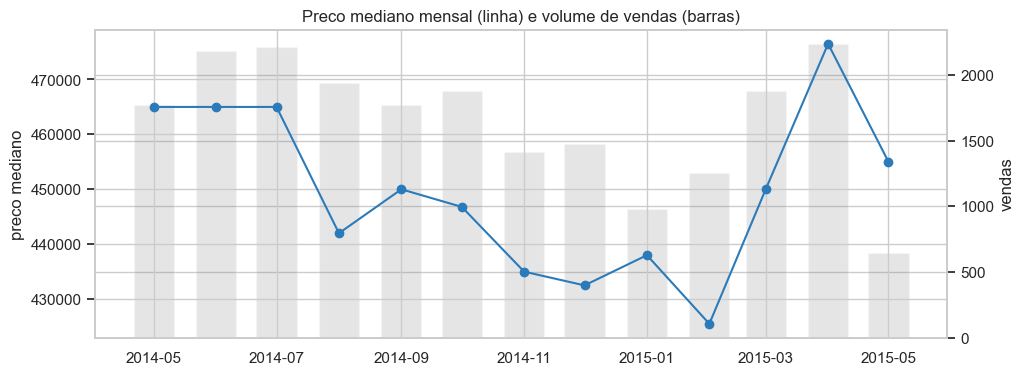

In [19]:
data_venda = F.to_date(F.substring(F.regexp_replace(col("date").cast("string"), "[^0-9]", ""), 1, 8), "yyyyMMdd")

mensal = (casas.groupBy(F.trunc(data_venda, "month").alias("mes"))
               .agg(F.percentile_approx(col("price"), 0.5).alias("preco_mediano"), F.count("*").alias("vendas"))
               .orderBy("mes")
               .toPandas())

fig, ax1 = plt.subplots(figsize=(11, 4))
ax2 = ax1.twinx()
ax2.bar(mensal.mes, mensal.vendas, width=20, alpha=0.2, color="gray")
ax1.plot(mensal.mes, mensal.preco_mediano, marker="o", color="#2b7bba")
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
ax1.set(title="Preco mediano mensal (linha) e volume de vendas (barras)", ylabel="preco mediano")
ax2.set(ylabel="vendas")
plt.show()

O preço mediano varia entre cerca de 430 e 470 mil no período, com sazonalidade: vendas e preços mais altos na primavera e no verão, e queda no inverno. Como `date` não existe no unseen, a data não entra como variável, mas pode ser usada para uma validação temporal (treinar no passado e testar no futuro).

## 8. EDA complementar: interações e padrões ocultos

Análises que a correlação individual não captura: preço do imóvel em relação ao tamanho dos vizinhos, prêmio de reforma condicionado à idade, efeito do porão, dispersão de preço dentro do CEP e o comportamento dos imóveis revendidos.

### 8.1 Área relativa aos vizinhos

O preço por pé² cai de forma monotônica conforme o imóvel é maior que os vizinhos: a mediana passa de 317 USD/pé² (razão < 0,8) para 223 USD/pé² (razão > 1,2), um prêmio de 42%. A menor casa da rua vale mais por pé²: o bairro valoriza o imóvel, e o tamanho absoluto não captura esse efeito.

**Candidata a variável:** razão `sqft_living / sqft_living15`.

,faixa,imoveis,preco_mediano_por_pe2
0,< 0.8,3487,316.783217
1,0.8-0.95,3996,257.246224
2,~1,5927,238.035714
3,1.05-1.2,3524,225.006410
4,> 1.2,4679,222.641509


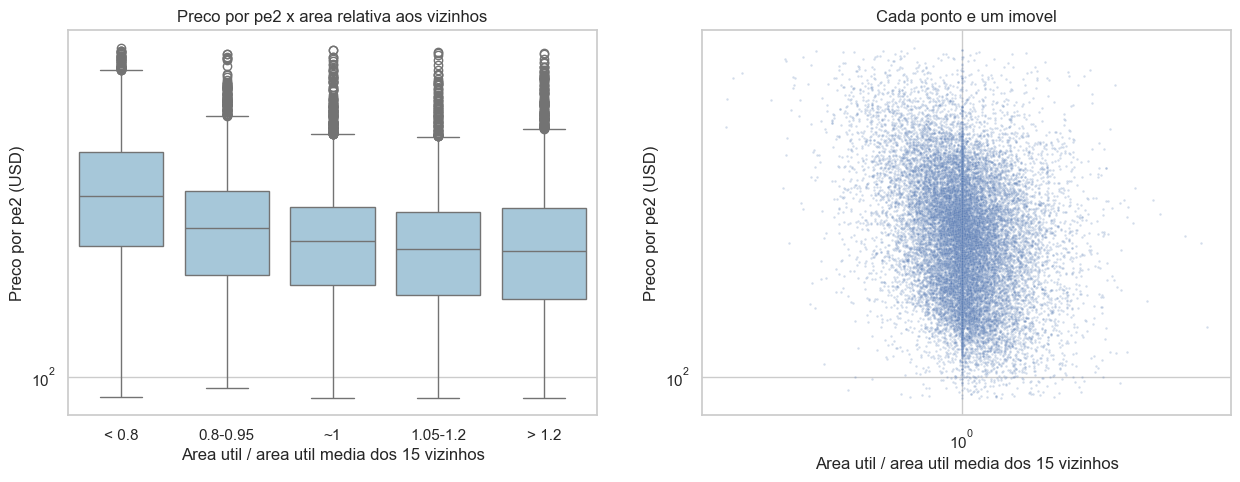

In [20]:
pdf = to_pd(casas, ["price_sqft", "sqft_living", "sqft_living15"])
pdf["razao_vizinhos"] = pdf.sqft_living / pdf.sqft_living15
pdf["faixa"] = pd.cut(pdf.razao_vizinhos, [0, 0.8, 0.95, 1.05, 1.2, np.inf],
                      labels=["< 0.8", "0.8-0.95", "~1", "1.05-1.2", "> 1.2"])

resumo = (pdf.groupby("faixa", observed=True)
            .agg(imoveis=("price_sqft", "size"), preco_mediano_por_pe2=("price_sqft", "median"))
            .reset_index())
display(resumo)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=pdf, x="faixa", y="price_sqft", ax=ax[0], color="#9ecae1")
ax[0].set(yscale="log", title="Preco por pe2 x area relativa aos vizinhos",
          xlabel="Area util / area util media dos 15 vizinhos", ylabel=rotulo("price_sqft"))
sns.scatterplot(data=pdf, x="razao_vizinhos", y="price_sqft", s=3, alpha=0.25, ax=ax[1])
ax[1].set(xscale="log", yscale="log", title="Cada ponto e um imovel",
          xlabel="Area util / area util media dos 15 vizinhos", ylabel=rotulo("price_sqft"))
plt.show()

### 8.2 Reforma, idade e porão

O prêmio de reforma existe em todas as faixas de idade, mas não é uniforme: cerca de 20% para imóveis de 20 a 30 anos e até 81% para 50 a 60 anos (na faixa de 0 a 10 anos não há reformados). Como o efeito depende da idade, variáveis como `yr_last_update` ou a diferença `yr_last_update - yr_built` capturam mais informação que `was_renovated` isolado.

O porão (39% dos imóveis) acompanha preço mediano 25% maior, mas parte do efeito se deve apenas à área útil maior, que `sqft_living` já captura.

,Idade do imovel em 2015 (anos),sem reforma,reformado,premio_reforma_pct
0,0-10,500000.0,NaN,NaN
1,10-20,507000.0,825000.0,63.0
2,20-30,460000.0,550000.0,20.0
3,30-40,440000.0,749000.0,70.0
4,40-50,385000.0,580000.0,51.0
5,50-60,384000.0,695750.0,81.0
6,60+,442950.0,594975.0,34.0


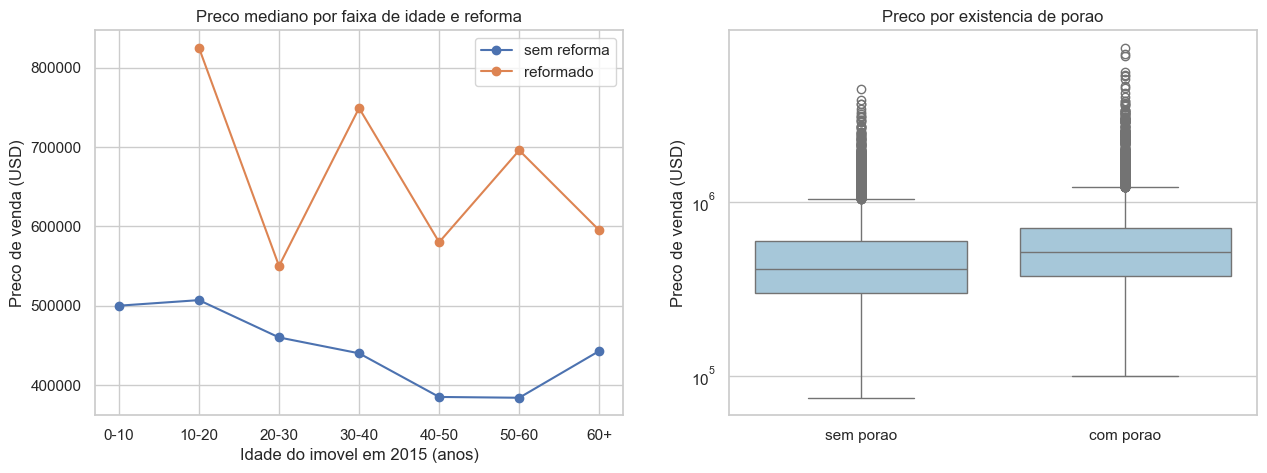

In [21]:
pdf = to_pd(casas, ["price", "house_age", "was_renovated", "sqft_basement", "sqft_living"])
pdf["porao"] = np.where(pdf.sqft_basement > 0, "com porao", "sem porao")
pdf["faixa_idade"] = pd.cut(pdf.house_age, [0, 10, 20, 30, 40, 50, 60, 120], include_lowest=True,
                            labels=["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60+"])

por_idade = (pdf.groupby(["faixa_idade", "was_renovated"], observed=True)["price"]
              .median().unstack())
por_idade.columns = ["sem reforma", "reformado"]
por_idade["premio_reforma_pct"] = 100 * (por_idade["reformado"] / por_idade["sem reforma"] - 1)
display(por_idade.round(0).reset_index().rename(columns={"faixa_idade": rotulo("house_age")}))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
por_idade[["sem reforma", "reformado"]].plot(marker="o", ax=ax[0])
ax[0].set(title="Preco mediano por faixa de idade e reforma", xlabel=rotulo("house_age"), ylabel=rotulo("price"))
sns.boxplot(data=pdf, x="porao", y="price", ax=ax[1], color="#9ecae1")
ax[1].set(yscale="log", title="Preco por existencia de porao", xlabel="", ylabel=rotulo("price"))
plt.show()

### 8.3 Dispersão de preço dentro do CEP

Mesmo dentro de um mesmo CEP, `log_price` tem desvio-padrão mediano de 0,35: o preço típico varia cerca de 42% acima ou abaixo da mediana do próprio CEP, e isso ocorre em todos os níveis de preço. O CEP define o patamar do bairro, mas a maior parte da variação vem das características individuais do imóvel.

Por isso o `zipcode` é usado apenas como chave de junção com a demografia, e não como variável do modelo. Como número, ele não tem ordem com significado. O patamar do bairro já chega ao modelo pela demografia do CEP e pela localização (`lat`, `long`).

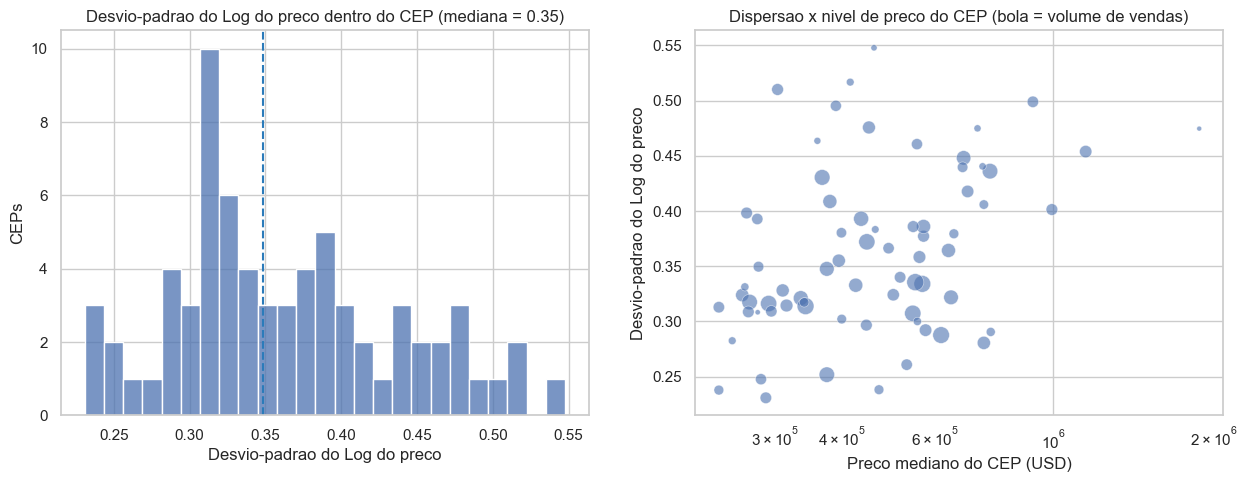

In [22]:
cep = (curto(casas).groupBy("zipcode")
       .agg(F.count("*").alias("vendas"),
            F.percentile_approx("price", 0.5).alias("preco_mediano"),
            F.stddev("log_price").alias("desvio_log_preco"))
       .toPandas())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(cep.desvio_log_preco, bins=25, ax=ax[0])
ax[0].axvline(cep.desvio_log_preco.median(), color="#2b7bba", ls="--")
ax[0].set(title=f"Desvio-padrao do {rotulo('log_price')} dentro do CEP (mediana = {cep.desvio_log_preco.median():.2f})",
          xlabel=f"Desvio-padrao do {rotulo('log_price')}", ylabel="CEPs")
sns.scatterplot(data=cep, x="preco_mediano", y="desvio_log_preco", s=cep.vendas / 4, alpha=0.6, ax=ax[1])
ax[1].set(xscale="log", title="Dispersao x nivel de preco do CEP (bola = volume de vendas)",
          xlabel="Preco mediano do CEP (USD)", ylabel=f"Desvio-padrao do {rotulo('log_price')}")
plt.show()

### 8.4 Revendas: saltos de preço entre vendas

Das 177 revendas consecutivas, 95% foram revendidas mais caro, com mediana de apenas 6 meses entre as vendas. A valorização anualizada é ruidosa e inflada justamente porque o intervalo é curto, e há saltos extremos, como de 85 mil para 235 mil em 3,5 meses.

Revendas consecutivas: 177 | meses entre vendas: mediana 6
Revendidas mais caro: 95%
Valorizacao ao ano: mediana 144%, p25 57%, p75 248%


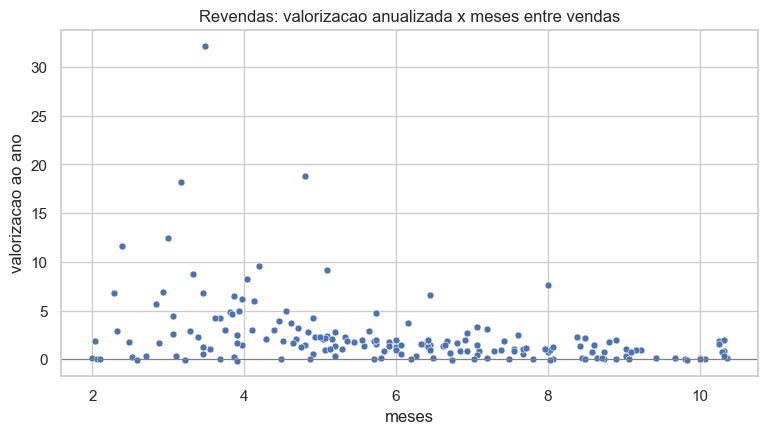

In [23]:
from pyspark.sql.window import Window

vendas = (curto(casas).select("id", "price", "date")
          .withColumn("data", F.to_date(F.substring(F.regexp_replace("date", "[^0-9]", ""), 1, 8), "yyyyMMdd")))

w_ordem = Window.partitionBy("id").orderBy("data")
rev = (vendas.withColumn("n_vendas", F.count("*").over(w_ordem.rowsBetween(Window.unboundedPreceding, Window.unboundedFollowing)))
             .filter("n_vendas >= 2")
             .withColumn("preco_anterior", F.lag("price").over(w_ordem))
             .withColumn("data_anterior", F.lag("data").over(w_ordem))
             .filter("preco_anterior is not null")
             .withColumn("meses", F.months_between("data", "data_anterior"))
             .filter("meses >= 1")
             .withColumn("valorizacao_ao_ano", F.pow(F.col("price") / F.col("preco_anterior"), 12.0 / F.col("meses")) - 1)
             .select("id", "meses", "preco_anterior", "price", "valorizacao_ao_ano"))

rpd = rev.toPandas()
print(f"Revendas consecutivas: {len(rpd)} | meses entre vendas: mediana {rpd.meses.median():.0f}")
print(f"Revendidas mais caro: {(rpd.price > rpd.preco_anterior).mean():.0%}")
print(f"Valorizacao ao ano: mediana {100 * rpd.valorizacao_ao_ano.median():.0f}%, "
      f"p25 {100 * rpd.valorizacao_ao_ano.quantile(.25):.0f}%, p75 {100 * rpd.valorizacao_ao_ano.quantile(.75):.0f}%")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=rpd, x="meses", y="valorizacao_ao_ano", s=25, ax=ax)
ax.axhline(0, color="gray", lw=0.8)
ax.set(title="Revendas: valorizacao anualizada x meses entre vendas", ylabel="valorizacao ao ano")
plt.show()

In [24]:
caso = (curto(casas).filter("id = 2422049104")
        .select("date", "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot",
                "condition", "grade", "sqft_above", "sqft_basement", "yr_built", "yr_renovated")
        .orderBy("date"))
display(caso.toPandas().rename(columns=rotulo))

# Generalizando: dos revendidos com salto >= 100%, algum teve caracteristica alterada entre as vendas?
rpd["salto_pct"] = 100 * (rpd.price / rpd.preco_anterior - 1)
extremos = rpd[rpd.salto_pct >= 100]
print(f"Revendas com salto >= 100%: {len(extremos)}")

if len(extremos) > 0:
    ids = ",".join(str(i) for i in extremos.id)
    alteradas = (curto(casas).filter(f"id in ({ids})")
                 .groupBy("id")
                 .agg(F.countDistinct("sqft_living").alias("n_sqft_living"),
                      F.countDistinct("grade").alias("n_grade"),
                      F.countDistinct("condition").alias("n_condition"),
                      F.countDistinct("yr_renovated").alias("n_yr_renovated"))
                 .filter("n_sqft_living > 1 or n_grade > 1 or n_condition > 1 or n_yr_renovated > 1"))
    print("Imoveis dessas revendas com alguma caracteristica alterada entre as vendas:", alteradas.count())

,Data da venda,Preco de venda (USD),Quartos,Banheiros (0.5 = lavabo),Area util (pes2),Area do terreno (pes2),Estado de conservacao (1 a 5),Padrao construtivo (1 a 13),Area acima do solo (pes2),Area do porao (pes2),Ano de construcao,Ano da reforma (0 = nunca)
0,20140915T000000,85000.0,2,1.0,830,9000,3,6,830,0,1939,0
1,20141230T000000,235000.0,2,1.0,830,9000,3,6,830,0,1939,0


Revendas com salto >= 100%: 21
Imoveis dessas revendas com alguma caracteristica alterada entre as vendas: 0


As duas vendas do imóvel 2422049104 (85 mil em set/2014 e 235 mil em dez/2014, um salto de 176% em 3,5 meses) têm características idênticas: mesma área de 830 pés², mesmo grade 6, mesma condição 3, sem reforma registrada. O padrão se repete: dos 21 imóveis revendidos com salto ≥ 100%, nenhum teve qualquer característica alterada entre as duas linhas.

A base registra as características, mas não capta o que mudou entre uma venda e outra. A reforma (ou uma primeira venda abaixo do mercado) é uma hipótese, não um fato observado. Por isso a primeira venda de um imóvel revendido não entra no treino como se fosse um imóvel independente: mantém-se apenas a venda mais recente.


### 8.5 Condition: efeito escondido pela idade e pelo padrão

Na correlação geral, `condition` parece não ter relação com o preço (Spearman 0,02). Isso acontece por um fator de confusão: os imóveis com nota 3 (65% da base) são mais novos (mediana de 1988) e de padrão mais alto (grade mediano 8), enquanto os de nota 4 e 5 são mais antigos (1950 a 1962) e de padrão mais baixo (grade 7). Os dois efeitos se cancelam.
Comparando imóveis do mesmo padrão construtivo, o efeito aparece: no grade 9, o preço mediano por pé² passa de 246 USD (condição 3) para 302 (condição 4) e 368 (condição 5), uma alta de 50%. O padrão se repete nos grades 7 e 8.

`condition` e `grade` medem coisas diferentes: o estado de conservação e o padrão construtivo. Um imóvel de padrão simples pode estar muito bem conservado. Por isso as duas variáveis são mantidas separadas, e a interação entre elas fica a cargo do modelo. Como limitação, `condition` é uma avaliação subjetiva e muito concentrada na nota 3, o que reduz o seu poder de discriminação.

,Estado de conservacao (1 a 5),imoveis,pct_imoveis,ano_construcao_mediano,grade_mediano,preco_pe2_mediano
0,1,30,0.1,1928,6,244.0
1,2,172,0.8,1950,7,210.0
2,3,14031,64.9,1988,8,239.0
3,4,5679,26.3,1962,7,250.0
4,5,1701,7.9,1950,7,285.0


Estado de conservacao (1 a 5),1,2,3,4,5
Padrao construtivo (1 a 13),,,,,
6,261.0,219.0,241.0,248.0,239.0
7,140.0,205.0,220.0,233.0,268.0
8,188.0,203.0,240.0,253.0,302.0
9,NaN,156.0,246.0,302.0,368.0


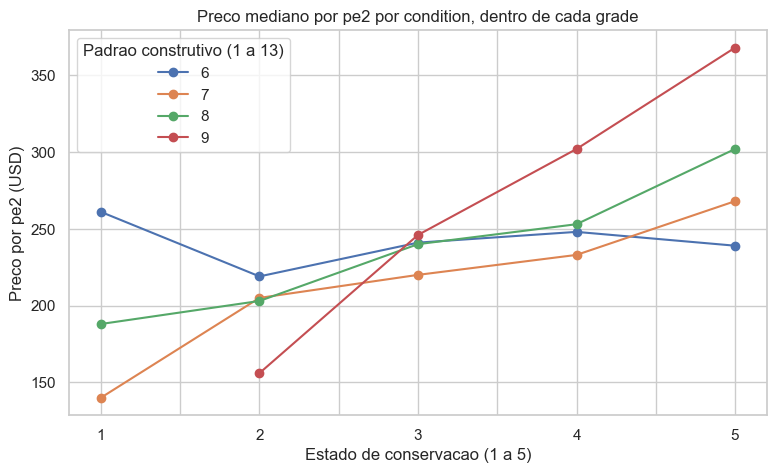

In [25]:
base = curto(casas)

perfil = (base.groupBy("condition")
              .agg(F.count("*").alias("imoveis"),
                   F.round(100 * F.count("*") / n, 1).alias("pct_imoveis"),
                   F.percentile_approx("yr_built", 0.5).alias("ano_construcao_mediano"),
                   F.percentile_approx("grade", 0.5).alias("grade_mediano"),
                   F.round(F.percentile_approx("price_sqft", 0.5), 0).alias("preco_pe2_mediano"))
              .orderBy("condition"))
display(perfil.toPandas().rename(columns=rotulo))

por_grade = (base.filter(F.col("grade").between(6, 9))
                 .groupBy("grade")
                 .pivot("condition")
                 .agg(F.round(F.percentile_approx("price_sqft", 0.5), 0))
                 .orderBy("grade")
                 .toPandas()
                 .set_index("grade"))
display(por_grade.rename_axis(index=rotulo("grade"), columns=rotulo("condition")))

ax = por_grade.T.plot(marker="o", figsize=(9, 5))
ax.set(title="Preco mediano por pe2 por condition, dentro de cada grade",
       xlabel=rotulo("condition"), ylabel=rotulo("price_sqft"))
ax.legend(title=rotulo("grade"))
plt.show()

## 9. Resumo e decisões

| Achado | Decisão | Resultado na modelagem |
|---|---|---|
| Preço com forte assimetria | Testar `log(price)` e `log(price / sqft)` como alvo, além dos alvos sem log | `log(price)` foi o melhor alvo |
| 176 imóveis vendidos mais de uma vez, com saltos de preço sem mudança registrada | Manter apenas a venda mais recente de cada imóvel | Aplicado na base de treino |
| 17 registros inconsistentes (0 quartos, 0 banheiros, 33 quartos) | Remover para preservar a integridade dos dados | Aplicado na base de treino |
| Valores extremos reais (terrenos grandes, alto padrão) | Manter, e testar o corte dos maiores imóveis (p95 e p99 da área útil) | Cortar não trouxe ganho: mantidos |
| `sqft_living = sqft_above + sqft_basement` | Testar com e sem `sqft_above` | Sem ganho ao remover: mantida |
| Junção por CEP com cobertura de 100% | Usar a demografia como perfil do bairro; `zipcode` só como chave | Testado sem a demografia; ela entra entre as variáveis mais importantes |
| 4 CEPs com demografia imputada | Registrar como limitação | Limitação |
| Escolaridade em contagem e percentual | Testar sem as contagens (`edctn_*_qty`) | Sem ganho ao remover: mantidas |
| Relações não lineares e não monotônicas (`lat`, `yr_built`) e colinearidade | Priorizar modelos de árvore | LightGBM, XGBoost e CatBoost |
| Imóvel menor que os vizinhos vale mais por pé² | Testar `sqft_living / sqft_living15` | Sem ganho: não incluída |
| Prêmio de reforma varia com a idade | Usar `yr_last_update` e testar os anos desde a última atualização | `yr_last_update` mantida; a nova variável não trouxe ganho |
| `condition` sem correlação geral, mas com efeito dentro do mesmo `grade` | Manter `condition` e `grade` separadas; interação capturada pelo modelo | Mantidas |
| `date` ausente no unseen | Não usar como variável | Fora do modelo |

## 10. Aplicação das decisões e gravação

Com base nas decisões acima, a base de treino é gerada aplicando:

1. Remoção dos 17 registros inconsistentes (0 quartos, 0 banheiros ou mais de 15 quartos).
2. Manutenção apenas da venda mais recente de cada imóvel revendido.
3. Junção com os dados demográficos por CEP.

As tabelas traduzidas (com as variáveis derivadas) e a base de treino são gravadas em arquivos novos, sem alterar os originais.

In [26]:
from pyspark.sql import Window

regra_inconsistente = (col("bedrooms") == 0) | (col("bedrooms") > 15) | (col("bathrooms") == 0)
ultima_venda = Window.partitionBy(col("id")).orderBy(col("date").desc())

casas_limpo = (casas.filter(~regra_inconsistente)
                    .withColumn("_ordem", F.row_number().over(ultima_venda))
                    .filter(F.col("_ordem") == 1)
                    .drop("_ordem"))

treino = casas_limpo.join(demo, on=C["zipcode"], how="left")
assert treino.count() == casas_limpo.count()

saidas = {
    "kc_house_data_traduzido": casas,
    "zipcode_demographics_traduzido": demo,
    "future_unseen_examples_traduzido": unseen,
    "kc_house_treino": treino,
}
for nome, tabela in saidas.items():
    caminho = f"{PASTA}\\{nome}.csv"
    tabela.toPandas().to_csv(caminho, index=False, encoding="utf-8-sig")
    print(f"{caminho}: {tabela.count()} linhas x {len(tabela.columns)} colunas")

C:\Users\PICHAU\Downloads\DESAFIO DATA SCIENCE\kc_house_data_traduzido.csv: 21613 linhas x 27 colunas
C:\Users\PICHAU\Downloads\DESAFIO DATA SCIENCE\zipcode_demographics_traduzido.csv: 70 linhas x 27 colunas
C:\Users\PICHAU\Downloads\DESAFIO DATA SCIENCE\future_unseen_examples_traduzido.csv: 100 linhas x 21 colunas
C:\Users\PICHAU\Downloads\DESAFIO DATA SCIENCE\kc_house_treino.csv: 21419 linhas x 53 colunas
